### Proyecto_Final_EBAC_Seguros

## Contexto y objetivo

Este notebook desarrolla el análisis final para una compañía de seguros de automóviles a partir de datos municipales de incidencia delictiva en México. El objetivo es transformar la base original en información útil para estimar exposición al riesgo automotriz, analizar patrones temporales, pronosticar la incidencia y clasificar entidades mediante técnicas de clustering.

El flujo se divide en cinco etapas: **1) carga y validación**, **2) selección y limpieza de delitos automotrices**, **3) serie de tiempo de Ecatepec de Morelos**, **4) clustering estatal 2021** y **5) preparación de datos para Looker Studio**.

> **Alcance:** los resultados representan incidencia delictiva observada. No equivalen directamente a probabilidad individual de siniestro porque no se incorporan variables de exposición como parque vehicular, número de pólizas o población.


In [1]:
%pip install matplotlib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ruta = r"C:\Users\samdl\Downloads\IDM_NM_dic25.csv"

df = pd.read_csv(
    ruta,
    encoding="latin1",
    low_memory=False
)

print("Filas:", df.shape[0])
print("Columnas:", df.shape[1])

df.head()

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Filas: 2562994
Columnas: 21


,Año,Clave_Ent,Entidad,Cve. Municipio,Municipio,Bien jurídico afectado,Tipo de delito,Subtipo de delito,Modalidad,Enero,...,Marzo,Abril,Mayo,Junio,Julio,Agosto,Septiembre,Octubre,Noviembre,Diciembre
0,2015,1,Aguascalientes,1001,Aguascalientes,La vida y la Integridad corporal,Homicidio,Homicidio doloso,Con arma de fuego,2,...,1,1,0,1,1,0,2,1,0,1
1,2015,1,Aguascalientes,1001,Aguascalientes,La vida y la Integridad corporal,Homicidio,Homicidio doloso,Con arma blanca,1,...,0,0,0,1,0,1,0,0,0,0
2,2015,1,Aguascalientes,1001,Aguascalientes,La vida y la Integridad corporal,Homicidio,Homicidio doloso,Con otro elemento,0,...,1,1,3,2,0,1,2,0,0,0
3,2015,1,Aguascalientes,1001,Aguascalientes,La vida y la Integridad corporal,Homicidio,Homicidio doloso,No especificado,1,...,0,1,0,0,0,0,0,0,0,0
4,2015,1,Aguascalientes,1001,Aguascalientes,La vida y la Integridad corporal,Homicidio,Homicidio culposo,Con arma de fuego,0,...,0,0,1,0,0,0,0,0,0,0


**Objetivo del paso.** Se importan las librerías principales y la base nacional de incidencia delictiva. `low_memory=False` evita que pandas infiera tipos por bloques en un archivo de gran tamaño. La codificación `latin1` se utiliza para conservar correctamente caracteres del archivo fuente.

**Observación.** Esta carga constituye la fuente maestra del proyecto; no se modifica el archivo original, sino que las transformaciones posteriores se realizan sobre copias en memoria.


In [2]:
df.columns.tolist()

['Año',
 'Clave_Ent',
 'Entidad',
 'Cve. Municipio',
 'Municipio',
 'Bien jurídico afectado',
 'Tipo de delito',
 'Subtipo de delito',
 'Modalidad',
 'Enero',
 'Febrero',
 'Marzo',
 'Abril',
 'Mayo',
 'Junio',
 'Julio',
 'Agosto',
 'Septiembre',
 'Octubre',
 'Noviembre',
 'Diciembre']

**Validación de estructura.** Se revisan los nombres de las columnas antes de cualquier transformación. Esto permite confirmar que están disponibles las variables geográficas, la clasificación del delito y los doce meses necesarios para construir la serie temporal.


In [3]:
df["Año"].min(), df["Año"].max()

(np.int64(2015), np.int64(2025))

**Cobertura temporal.** Se identifica el primer y último año disponibles en la fuente. Aunque la base contiene información posterior a 2022, el proyecto utilizará 2015–2021 para entrenamiento y 2022 como periodo de validación del pronóstico.


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2562994 entries, 0 to 2562993
Data columns (total 21 columns):
 #   Column                  Dtype
---  ------                  -----
 0   Año                     int64
 1   Clave_Ent               int64
 2   Entidad                 str  
 3   Cve. Municipio          int64
 4   Municipio               str  
 5   Bien jurídico afectado  str  
 6   Tipo de delito          str  
 7   Subtipo de delito       str  
 8   Modalidad               str  
 9   Enero                   int64
 10  Febrero                 int64
 11  Marzo                   int64
 12  Abril                   int64
 13  Mayo                    int64
 14  Junio                   int64
 15  Julio                   int64
 16  Agosto                  int64
 17  Septiembre              int64
 18  Octubre                 int64
 19  Noviembre               int64
 20  Diciembre               int64
dtypes: int64(15), str(6)
memory usage: 410.6 MB


**Diagnóstico inicial.** `df.info()` permite verificar dimensiones, tipos de datos y uso de memoria. La base contiene más de 2.5 millones de registros y 21 columnas, por lo que conviene filtrar y transformar únicamente las variables relevantes para reducir el costo computacional.


## 1. Exploración y selección de delitos relacionados con el riesgo automotriz

Antes de definir las variables utilizadas para medir el riesgo asociado a seguros de automóviles, se exploran categorías, subtipos y modalidades disponibles en la base. El objetivo es identificar, a partir del catálogo completo, los delitos con relación directa o potencial con el uso y propiedad de vehículos. Esta etapa documenta que la selección final se realizó después de revisar las alternativas disponibles.


In [5]:
# Obtener catálogo de subtipos de delito

catalogo_subtipos = (
    df[["Tipo de delito", "Subtipo de delito"]]
    .drop_duplicates()
    .sort_values(["Tipo de delito", "Subtipo de delito"])
    .reset_index(drop=True)
)

catalogo_subtipos

,Tipo de delito,Subtipo de delito
0,Aborto,Aborto
1,Abuso de confianza,Abuso de confianza
2,Abuso sexual,Abuso sexual
3,Acoso sexual,Acoso sexual
4,Allanamiento de morada,Allanamiento de morada
5,Amenazas,Amenazas
6,Contra el medio ambiente,Contra el medio ambiente
7,Corrupción de menores,Corrupción de menores
8,Daño a la propiedad,Daño a la propiedad
9,Delitos cometidos por servidores públicos,Delitos cometidos por servidores públicos


**Exploración del catálogo.** Antes de elegir los delitos del análisis se construye un catálogo único de tipo y subtipo. La intención es evitar una selección arbitraria y documentar que se revisó la estructura completa disponible en la fuente.


In [6]:
palabras_clave = [
    "vehículo",
    "autopartes",
    "transportista",
    "transporte",
    "coche",
    "motocicleta"
]

patron = "|".join(palabras_clave)

candidatos_auto = df[
    df["Subtipo de delito"].str.contains(
        patron,
        case=False,
        na=False
    ) |
    df["Modalidad"].str.contains(
        patron,
        case=False,
        na=False
    )
][
    ["Tipo de delito", "Subtipo de delito", "Modalidad"]
].drop_duplicates().sort_values(
    ["Subtipo de delito", "Modalidad"]
).reset_index(drop=True)

candidatos_auto

,Tipo de delito,Subtipo de delito,Modalidad
0,Robo,Robo a transportista,Con violencia
1,Robo,Robo a transportista,Sin violencia
2,Robo,Robo de autopartes,Con violencia
3,Robo,Robo de autopartes,Sin violencia
4,Robo,Robo de vehículo automotor,Robo de coche de 4 ruedas Con violencia
5,Robo,Robo de vehículo automotor,Robo de coche de 4 ruedas Sin violencia
6,Robo,Robo de vehículo automotor,Robo de embarcaciones pequeñas y grandes Con v...
7,Robo,Robo de vehículo automotor,Robo de embarcaciones pequeñas y grandes Sin v...
8,Robo,Robo de vehículo automotor,Robo de motocicleta Con violencia
9,Robo,Robo de vehículo automotor,Robo de motocicleta Sin violencia


**Búsqueda de candidatos automotrices.** Se realiza una búsqueda amplia mediante palabras clave asociadas con vehículos y transporte. Este filtro es deliberadamente inclusivo: su propósito es generar candidatos para revisión, no definir todavía el universo final del seguro de automóvil.

**Observación.** La exploración recuperó categorías como transporte público, transportistas, motocicletas y autopartes. Posteriormente se restringe el alcance a riesgos directamente vinculados con un automóvil particular asegurado.


### Selección de delitos relacionados con el riesgo automotriz

A partir de la exploración del catálogo completo de delitos se identificaron
16 combinaciones de subtipo y modalidad potencialmente relacionadas con
vehículos o transporte.

Para el análisis se seleccionaron aquellas categorías que representan de forma
directa un riesgo sobre un automóvil particular asegurado.

Se incluyeron:

- Robo de vehículo automotor, específicamente la modalidad de coche de
  cuatro ruedas, tanto con violencia como sin violencia.
- Robo de autopartes, tanto con violencia como sin violencia.

Se excluyeron delitos relacionados con transporte público, transporte
individual y robo a transportistas debido a que representan principalmente
riesgos asociados a pasajeros, transporte comercial o mercancías.

También se excluyeron motocicletas y embarcaciones, debido a que el alcance
del análisis se limita al riesgo asociado a automóviles de cuatro ruedas.

Esta selección permite construir indicadores de riesgo directamente
relacionados con potenciales siniestros cubiertos por una póliza de automóvil.

In [7]:
# 1. Robo de autopartes
autopartes = (
    df["Subtipo de delito"] == "Robo de autopartes"
)

# 2. Robo de automóviles de cuatro ruedas
automoviles = (
    (df["Subtipo de delito"] == "Robo de vehículo automotor") &
    (df["Modalidad"].str.contains("coche de 4 ruedas", case=False, na=False))
)

# Dataset de delitos relevantes para seguros de automóvil
df_auto = df[autopartes | automoviles].copy()

print("Registros base original:", f"{len(df):,}")
print("Registros seleccionados:", f"{len(df_auto):,}")
print(
    "Reducción:",
    f"{(1 - len(df_auto)/len(df))*100:.2f}%"
)

df_auto.head()

Registros base original: 2,562,994
Registros seleccionados: 104,612
Reducción: 95.92%


,Año,Clave_Ent,Entidad,Cve. Municipio,Municipio,Bien jurídico afectado,Tipo de delito,Subtipo de delito,Modalidad,Enero,...,Marzo,Abril,Mayo,Junio,Julio,Agosto,Septiembre,Octubre,Noviembre,Diciembre
41,2015,1,Aguascalientes,1001,Aguascalientes,El patrimonio,Robo,Robo de vehículo automotor,Robo de coche de 4 ruedas Con violencia,4,...,4,3,0,1,1,5,2,5,6,4
42,2015,1,Aguascalientes,1001,Aguascalientes,El patrimonio,Robo,Robo de vehículo automotor,Robo de coche de 4 ruedas Sin violencia,114,...,122,124,138,94,89,93,126,105,152,171
47,2015,1,Aguascalientes,1001,Aguascalientes,El patrimonio,Robo,Robo de autopartes,Con violencia,0,...,0,0,0,0,0,0,0,0,0,0
48,2015,1,Aguascalientes,1001,Aguascalientes,El patrimonio,Robo,Robo de autopartes,Sin violencia,94,...,137,108,0,0,0,0,0,0,0,0
139,2015,1,Aguascalientes,1002,Asientos,El patrimonio,Robo,Robo de vehículo automotor,Robo de coche de 4 ruedas Con violencia,0,...,0,0,0,0,0,0,0,1,0,1


**Construcción del universo analítico.** Se conservan únicamente el robo de autopartes y el robo de vehículo automotor en la modalidad “coche de 4 ruedas”, tanto con como sin violencia. Esta decisión alinea el conjunto de datos con el problema de negocio de una aseguradora de automóviles y evita mezclar riesgos de transporte público, carga, motocicletas o embarcaciones.


In [8]:
df_auto[
    ["Tipo de delito", "Subtipo de delito", "Modalidad"]
].drop_duplicates().sort_values(
    ["Subtipo de delito", "Modalidad"]
)

,Tipo de delito,Subtipo de delito,Modalidad
47,Robo,Robo de autopartes,Con violencia
48,Robo,Robo de autopartes,Sin violencia
41,Robo,Robo de vehículo automotor,Robo de coche de 4 ruedas Con violencia
42,Robo,Robo de vehículo automotor,Robo de coche de 4 ruedas Sin violencia


**Control de calidad de la selección.** Se muestran las combinaciones finales de tipo, subtipo y modalidad para comprobar que el filtro no incorporó categorías ajenas al alcance definido.


In [9]:
# Revisar valores nulos en el dataset seleccionado

nulos = df_auto.isnull().sum()

nulos[nulos > 0].sort_values(ascending=False)

Series([], dtype: int64)

**Valores faltantes.** Se revisan los nulos antes de transformar los datos. Cualquier ausencia en campos geográficos, de clasificación o en los valores mensuales podría sesgar agregaciones posteriores; por ello esta verificación forma parte del control de calidad.


In [10]:
# Revisar registros duplicados

duplicados = df_auto.duplicated().sum()

print("Registros duplicados:", duplicados)

Registros duplicados: 0


**Duplicados.** Se verifica si existen filas completamente duplicadas. La presencia de duplicados podría inflar artificialmente la incidencia delictiva y alterar rankings, modelos de series de tiempo y clusters.


## 2. Limpieza y transformación de los datos


In [11]:
# Columnas correspondientes a los meses

meses = [
    "Enero", "Febrero", "Marzo", "Abril",
    "Mayo", "Junio", "Julio", "Agosto",
    "Septiembre", "Octubre", "Noviembre", "Diciembre"
]

# Transformar de formato ancho a formato largo

df_auto_long = df_auto.melt(
    id_vars=[
        "Año",
        "Clave_Ent",
        "Entidad",
        "Cve. Municipio",
        "Municipio",
        "Bien jurídico afectado",
        "Tipo de delito",
        "Subtipo de delito",
        "Modalidad"
    ],
    value_vars=meses,
    var_name="Mes",
    value_name="Delitos"
)

print("Dimensiones:", df_auto_long.shape)

df_auto_long.head()

Dimensiones: (1255344, 11)


,Año,Clave_Ent,Entidad,Cve. Municipio,Municipio,Bien jurídico afectado,Tipo de delito,Subtipo de delito,Modalidad,Mes,Delitos
0,2015,1,Aguascalientes,1001,Aguascalientes,El patrimonio,Robo,Robo de vehículo automotor,Robo de coche de 4 ruedas Con violencia,Enero,4
1,2015,1,Aguascalientes,1001,Aguascalientes,El patrimonio,Robo,Robo de vehículo automotor,Robo de coche de 4 ruedas Sin violencia,Enero,114
2,2015,1,Aguascalientes,1001,Aguascalientes,El patrimonio,Robo,Robo de autopartes,Con violencia,Enero,0
3,2015,1,Aguascalientes,1001,Aguascalientes,El patrimonio,Robo,Robo de autopartes,Sin violencia,Enero,94
4,2015,1,Aguascalientes,1002,Asientos,El patrimonio,Robo,Robo de vehículo automotor,Robo de coche de 4 ruedas Con violencia,Enero,0


**Transformación de formato ancho a largo.** La fuente almacena cada mes en una columna distinta. Mediante `melt` se crea una fila por combinación registro–mes, dejando `Mes` y `Delitos` como variables. Este formato es más adecuado para análisis temporal, agregaciones y herramientas de visualización como Looker Studio.


In [12]:
# Número correspondiente a cada mes

mapa_meses = {
    "Enero": 1,
    "Febrero": 2,
    "Marzo": 3,
    "Abril": 4,
    "Mayo": 5,
    "Junio": 6,
    "Julio": 7,
    "Agosto": 8,
    "Septiembre": 9,
    "Octubre": 10,
    "Noviembre": 11,
    "Diciembre": 12
}

df_auto_long["Mes_num"] = df_auto_long["Mes"].map(mapa_meses)

df_auto_long["Fecha"] = pd.to_datetime(
    dict(
        year=df_auto_long["Año"],
        month=df_auto_long["Mes_num"],
        day=1
    )
)

df_auto_long[
    ["Año", "Mes", "Mes_num", "Fecha", "Entidad", "Municipio", "Delitos"]
].head(15)

,Año,Mes,Mes_num,Fecha,Entidad,Municipio,Delitos
0,2015,Enero,1,2015-01-01,Aguascalientes,Aguascalientes,4
1,2015,Enero,1,2015-01-01,Aguascalientes,Aguascalientes,114
2,2015,Enero,1,2015-01-01,Aguascalientes,Aguascalientes,0
3,2015,Enero,1,2015-01-01,Aguascalientes,Aguascalientes,94
4,2015,Enero,1,2015-01-01,Aguascalientes,Asientos,0
5,2015,Enero,1,2015-01-01,Aguascalientes,Asientos,0
6,2015,Enero,1,2015-01-01,Aguascalientes,Asientos,0
7,2015,Enero,1,2015-01-01,Aguascalientes,Asientos,0
8,2015,Enero,1,2015-01-01,Aguascalientes,Calvillo,0
9,2015,Enero,1,2015-01-01,Aguascalientes,Calvillo,3


**Creación de una fecha analítica.** Los nombres de mes se convierten a números y posteriormente a una fecha mensual con día 1. Con ello se obtiene una variable cronológica ordenable y compatible con modelos de series de tiempo.


In [13]:
# Crear categoría de riesgo automotriz

def clasificar_delito(row):

    if row["Subtipo de delito"] == "Robo de autopartes":
        return "Robo de autopartes"

    elif (
        row["Subtipo de delito"] == "Robo de vehículo automotor"
        and "Con violencia" in row["Modalidad"]
    ):
        return "Robo de automóvil con violencia"

    elif (
        row["Subtipo de delito"] == "Robo de vehículo automotor"
        and "Sin violencia" in row["Modalidad"]
    ):
        return "Robo de automóvil sin violencia"

    return "Otro"


df_auto_long["Categoria_riesgo"] = df_auto_long.apply(
    clasificar_delito,
    axis=1
)

df_auto_long["Categoria_riesgo"].value_counts()

Categoria_riesgo
Robo de autopartes                 627672
Robo de automóvil con violencia    313836
Robo de automóvil sin violencia    313836
Name: count, dtype: int64

**Variable de negocio.** Las modalidades seleccionadas se traducen a tres categorías fáciles de interpretar: robo de autopartes, robo de automóvil con violencia y robo de automóvil sin violencia. Esta clasificación simplifica el análisis y conecta la estructura técnica de la fuente con riesgos relevantes para una aseguradora.


In [14]:
print("Periodo:")
print(df_auto_long["Fecha"].min(), "→", df_auto_long["Fecha"].max())

print("\nEntidades:")
print(df_auto_long["Entidad"].nunique())

print("\nMunicipios:")
print(df_auto_long["Municipio"].nunique())

print("\nDelitos registrados:")
print(f'{df_auto_long["Delitos"].sum():,}')

print("\nCategorías:")
print(df_auto_long["Categoria_riesgo"].value_counts())

Periodo:
2015-01-01 00:00:00 → 2025-12-01 00:00:00

Entidades:
32

Municipios:
2337

Delitos registrados:
1,581,579

Categorías:
Categoria_riesgo
Robo de autopartes                 627672
Robo de automóvil con violencia    313836
Robo de automóvil sin violencia    313836
Name: count, dtype: int64


**Resumen del universo final.** Se valida la cobertura temporal, geográfica y el volumen total de delitos después de las transformaciones. Este punto funciona como control de consistencia antes de iniciar el análisis estadístico.


In [15]:
# Delitos reales por categoría de riesgo

resumen_categorias = (
    df_auto_long
    .groupby("Categoria_riesgo", as_index=False)["Delitos"]
    .sum()
    .sort_values("Delitos", ascending=False)
)

resumen_categorias["Porcentaje"] = (
    resumen_categorias["Delitos"] /
    resumen_categorias["Delitos"].sum() * 100
).round(2)

resumen_categorias

,Categoria_riesgo,Delitos,Porcentaje
1,Robo de automóvil sin violencia,894617,56.56
0,Robo de automóvil con violencia,490939,31.04
2,Robo de autopartes,196023,12.39


**Composición del riesgo.** Se cuantifica cuánto aporta cada categoría al total de delitos automotrices. Este resumen permite distinguir si el riesgo está impulsado principalmente por robo total del vehículo, violencia o robo parcial de autopartes.


## 3. Preparación del periodo de análisis y selección del municipio


In [16]:
df_proyecto = df_auto_long[
    df_auto_long["Año"].between(2015, 2022)
].copy()

print(
    "Periodo del proyecto:",
    df_proyecto["Fecha"].min(),
    "→",
    df_proyecto["Fecha"].max()
)

print("Delitos:", f'{df_proyecto["Delitos"].sum():,}')

Periodo del proyecto: 2015-01-01 00:00:00 → 2022-12-01 00:00:00
Delitos: 1,262,874


**Ventana del proyecto.** Aunque la fuente contiene años adicionales, se limita el análisis principal a 2015–2022. Los años 2015–2021 se usarán para estudiar patrones históricos y 2022 para evaluar el desempeño predictivo fuera de muestra.


In [17]:
train = df_proyecto[
    df_proyecto["Año"].between(2015, 2021)
].copy()

**Separación temporal.** Se crea el conjunto de entrenamiento con 2015–2021. Mantener 2022 fuera del entrenamiento evita fuga de información y permite una evaluación más realista del pronóstico.


In [18]:
riesgo_municipal = (
    train
    .groupby(
        ["Clave_Ent", "Entidad", "Cve. Municipio", "Municipio"],
        as_index=False
    )["Delitos"]
    .sum()
    .sort_values("Delitos", ascending=False)
)

riesgo_municipal.head(20)

,Clave_Ent,Entidad,Cve. Municipio,Municipio,Delitos
699,15,México,15033,Ecatepec de Morelos,60121
14,2,Baja California,2004,Tijuana,53656
579,14,Jalisco,14039,Guadalajara,48519
770,15,México,15104,Tlalnepantla de Baz,27299
12,2,Baja California,2002,Mexicali,25724
1696,21,Puebla,21114,Puebla,23382
660,14,Jalisco,14120,Zapopan,22432
1813,22,Querétaro,22014,Querétaro,21103
772,15,México,15106,Toluca,18846
723,15,México,15057,Naucalpan de Juárez,18346


**Selección objetiva del municipio.** Se agregan todos los delitos automotrices por municipio durante 2015–2021 y se ordenan de mayor a menor. El ranking sirve para seleccionar un caso de estudio con alta relevancia aseguradora en lugar de elegir un municipio de forma subjetiva.


In [19]:
# Quien tiene más robos de automoviles?

ranking_autos = (
    train[
        train["Categoria_riesgo"].str.contains(
            "Robo de automóvil",
            na=False
        )
    ]
    .groupby(
        ["Clave_Ent", "Entidad", "Cve. Municipio", "Municipio"],
        as_index=False
    )["Delitos"]
    .sum()
    .sort_values("Delitos", ascending=False)
)

ranking_autos.head(20)

,Clave_Ent,Entidad,Cve. Municipio,Municipio,Delitos
699,15,México,15033,Ecatepec de Morelos,58619
14,2,Baja California,2004,Tijuana,53429
579,14,Jalisco,14039,Guadalajara,40965
770,15,México,15104,Tlalnepantla de Baz,26305
12,2,Baja California,2002,Mexicali,25680
1696,21,Puebla,21114,Puebla,21134
660,14,Jalisco,14120,Zapopan,19541
772,15,México,15106,Toluca,17615
1813,22,Querétaro,22014,Querétaro,17604
723,15,México,15057,Naucalpan de Juárez,17387


**Validación por robo de automóvil.** Se repite el ranking considerando únicamente las categorías de robo de automóvil. Esto permite comprobar si el municipio con mayor riesgo total también concentra el principal riesgo de pérdida del vehículo.


In [20]:
# Quien tiene más robos de autopartes?
ranking_autopartes = (
    train[
        train["Categoria_riesgo"] == "Robo de autopartes"
    ]
    .groupby(
        ["Clave_Ent", "Entidad", "Cve. Municipio", "Municipio"],
        as_index=False
    )["Delitos"]
    .sum()
    .sort_values("Delitos", ascending=False)
)

ranking_autopartes.head(20)

,Clave_Ent,Entidad,Cve. Municipio,Municipio,Delitos
286,9,Ciudad de México,9014,Benito Juárez,9260
287,9,Ciudad de México,9015,Cuauhtémoc,8252
579,14,Jalisco,14039,Guadalajara,7554
0,1,Aguascalientes,1001,Aguascalientes,5833
911,17,Morelos,17007,Cuernavaca,5637
277,9,Ciudad de México,9005,Gustavo A. Madero,4513
279,9,Ciudad de México,9007,Iztapalapa,3818
275,9,Ciudad de México,9003,Coyoacán,3719
1813,22,Querétaro,22014,Querétaro,3499
1857,24,San Luis Potosí,24028,San Luis Potosí,2961


**Validación por autopartes.** Se analiza por separado el robo de autopartes. La comparación revela que distintos municipios pueden tener perfiles de riesgo diferentes, una idea que posteriormente también aparecerá en el clustering estatal.


- Ecatepec de Morelos fue seleccionado para el análisis de series de tiempo debido a que presentó la mayor incidencia acumulada de delitos relacionados con automóviles durante el periodo 2015–2021, con 60,121 casos. De ellos, 58,619 correspondieron a robo de automóvil, lo que representa aproximadamente el 97.5% del riesgo automotriz analizado en el municipio. Su elevada incidencia y relevancia dentro del riesgo asegurador lo convierten en un caso adecuado para analizar el comportamiento histórico y estimar la incidencia esperada durante 2022.

## 4. Análisis de series de tiempo: Ecatepec de Morelos


In [21]:
# Seleccionar Ecatepec de Morelos

ecatepec = df_proyecto[
    (df_proyecto["Clave_Ent"] == 15) &
    (df_proyecto["Cve. Municipio"] == 15033)
].copy()

# Agregar delitos por mes

serie_ecatepec = (
    ecatepec
    .groupby("Fecha", as_index=False)["Delitos"]
    .sum()
    .sort_values("Fecha")
)

serie_ecatepec.head(15)

,Fecha,Delitos
0,2015-01-01,798
1,2015-02-01,748
2,2015-03-01,742
3,2015-04-01,737
4,2015-05-01,862
5,2015-06-01,828
6,2015-07-01,819
7,2015-08-01,881
8,2015-09-01,897
9,2015-10-01,888


**Serie mensual de Ecatepec.** Una vez seleccionado el municipio, se agregan sus delitos por fecha. El resultado es una única serie mensual que resume la incidencia automotriz y que será la entrada de los modelos ARIMA/SARIMA.


In [22]:
print("Inicio:", serie_ecatepec["Fecha"].min())
print("Fin:", serie_ecatepec["Fecha"].max())
print("Meses disponibles:", len(serie_ecatepec))

serie_ecatepec.tail()

Inicio: 2015-01-01 00:00:00
Fin: 2022-12-01 00:00:00
Meses disponibles: 96


,Fecha,Delitos
91,2022-08-01,400
92,2022-09-01,328
93,2022-10-01,346
94,2022-11-01,284
95,2022-12-01,258


**Completitud temporal.** Se comprueba el inicio, fin y número de meses disponibles. Una serie mensual continua es indispensable para interpretar estacionalidad y ajustar correctamente modelos temporales.


In [23]:
train_ecatepec = serie_ecatepec[
    serie_ecatepec["Fecha"].dt.year <= 2021
].copy()

test_ecatepec = serie_ecatepec[
    serie_ecatepec["Fecha"].dt.year == 2022
].copy()

print("Meses entrenamiento:", len(train_ecatepec))
print("Meses prueba:", len(test_ecatepec))

print("\nPeriodo entrenamiento:")
print(
    train_ecatepec["Fecha"].min(),
    "→",
    train_ecatepec["Fecha"].max()
)

print("\nPeriodo prueba:")
print(
    test_ecatepec["Fecha"].min(),
    "→",
    test_ecatepec["Fecha"].max()
)

Meses entrenamiento: 84
Meses prueba: 12

Periodo entrenamiento:
2015-01-01 00:00:00 → 2021-12-01 00:00:00

Periodo prueba:
2022-01-01 00:00:00 → 2022-12-01 00:00:00


**Entrenamiento y prueba.** Se separan explícitamente 84 meses de 2015–2021 para entrenamiento y los 12 meses de 2022 para prueba. La evaluación sobre un año completo permite comparar el pronóstico con observaciones que el modelo nunca vio durante su ajuste.


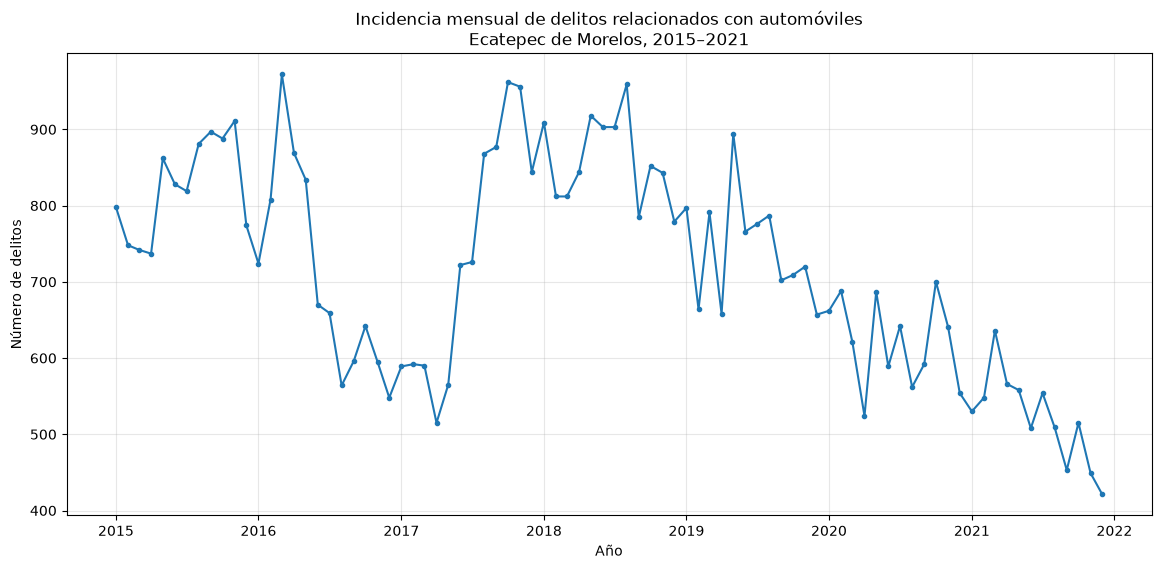

In [24]:
plt.figure(figsize=(14, 6))

plt.plot(
    train_ecatepec["Fecha"],
    train_ecatepec["Delitos"],
    marker="o",
    markersize=3
)

plt.title(
    "Incidencia mensual de delitos relacionados con automóviles\n"
    "Ecatepec de Morelos, 2015–2021"
)

plt.xlabel("Año")
plt.ylabel("Número de delitos")
plt.grid(alpha=0.3)

plt.show()

**Exploración visual de la serie.** La gráfica muestra variaciones importantes en el nivel mensual, con periodos de crecimiento y descenso. A partir de 2018 se aprecia una trayectoria general descendente, aunque persisten oscilaciones mensuales. Esto sugiere que la serie puede requerir diferenciación y que vale la pena investigar un componente estacional.


In [25]:
serie_train = (
    train_ecatepec
    .set_index("Fecha")["Delitos"]
    .asfreq("MS")
)

serie_train.head()

Fecha
2015-01-01    798
2015-02-01    748
2015-03-01    742
2015-04-01    737
2015-05-01    862
Freq: MS, Name: Delitos, dtype: int64

**Frecuencia mensual explícita.** La fecha se establece como índice y se fija la frecuencia `MS` (inicio de mes). Esto ayuda a `statsmodels` a reconocer correctamente la periodicidad de la serie.


In [26]:
print("Observaciones:", len(serie_train))
print("Valores nulos:", serie_train.isna().sum())

Observaciones: 84
Valores nulos: 0


**Control de continuidad.** Se comprueba que la serie no tenga meses faltantes después de fijar la frecuencia. Los huecos temporales podrían distorsionar la descomposición, ACF/PACF y los pronósticos.


In [27]:
%pip install statsmodels

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


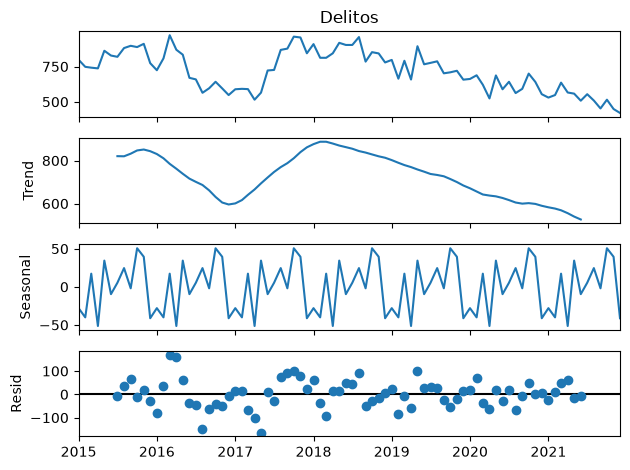

In [28]:
from statsmodels.tsa.seasonal import seasonal_decompose

descomposicion = seasonal_decompose(
    serie_train,
    model="additive",
    period=12
)

descomposicion.plot()
plt.show()

**Descomposición estacional.** Se utiliza un modelo aditivo con periodo 12 para separar nivel observado, tendencia, estacionalidad anual y residuo. El supuesto aditivo es razonable cuando la amplitud de las oscilaciones estacionales no crece proporcionalmente con el nivel de la serie.


- ### Descomposición de la serie temporal

La descomposición de la serie mensual de delitos relacionados con automóviles
en Ecatepec de Morelos permite identificar tres componentes principales.

La tendencia muestra cambios importantes a lo largo del periodo. Después de una
disminución entre 2016 y 2017, la incidencia aumentó nuevamente hasta alcanzar
uno de sus niveles más altos alrededor de 2018. A partir de ese momento se
observa una tendencia general descendente que continúa hasta finales de 2021.

El componente estacional presenta un patrón que se repite aproximadamente cada
12 meses, lo que sugiere la existencia de estacionalidad anual en la incidencia
de estos delitos.

Finalmente, los residuos representan las variaciones que no son explicadas por
la tendencia ni por el patrón estacional. Aunque se observan algunas
desviaciones importantes, éstos fluctúan alrededor de cero.

Estos resultados sugieren que el modelo de pronóstico debe considerar tanto
la evolución de la tendencia como la posible estacionalidad anual de la serie.

In [29]:
from statsmodels.tsa.stattools import adfuller

resultado_adf = adfuller(serie_train)

print(f"ADF Statistic: {resultado_adf[0]:.4f}")
print(f"p-value: {resultado_adf[1]:.4f}")

print("\nValores críticos:")
for clave, valor in resultado_adf[4].items():
    print(f"{clave}: {valor:.4f}")

ADF Statistic: -1.3109
p-value: 0.6241

Valores críticos:
1%: -3.5127
5%: -2.8975
10%: -2.5859


C:\Users\samdl\AppData\Local\Temp\ipykernel_29320\4226533323.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  resultado_adf = adfuller(serie_train)


**Resultado ADF.** El estadístico fue **-1.3109** y el `p-value` **0.6241**. Al ser mayor que 0.05, no se rechaza la hipótesis de raíz unitaria: la serie original no puede considerarse estacionaria. Esto justifica aplicar diferenciación antes del modelado.


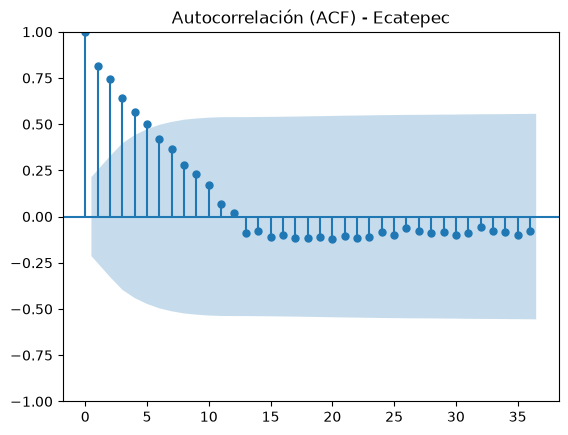

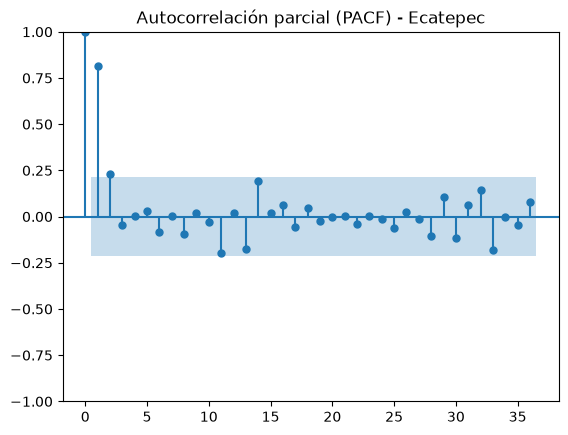

In [30]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

plot_acf(serie_train, lags=36)
plt.title("Autocorrelación (ACF) - Ecatepec")
plt.show()

plot_pacf(serie_train, lags=36, method="ywm")
plt.title("Autocorrelación parcial (PACF) - Ecatepec")
plt.show()

**ACF y PACF.** La autocorrelación disminuye lentamente en varios rezagos y la PACF muestra un efecto fuerte en el primer rezago. En conjunto con la prueba ADF, este comportamiento es consistente con una serie no estacionaria y orienta la exploración de especificaciones ARIMA/SARIMA con diferenciación.


- ### Prueba de estacionariedad

Para evaluar la estacionariedad de la serie se aplicó la prueba de
Dickey-Fuller Aumentada (ADF).

En la serie original se obtuvo un estadístico ADF de -1.3109 y un p-value
de 0.6241. Debido a que el p-value es superior al nivel de significancia
de 0.05, no se rechaza la hipótesis nula de presencia de raíz unitaria.

Por lo tanto, no existe evidencia suficiente para considerar estacionaria
la serie original. Este resultado es consistente con los cambios de
tendencia observados gráficamente.

En consecuencia, se evaluó la primera diferencia de la serie con el objetivo
de estabilizar su comportamiento antes de ajustar los modelos de pronóstico.

In [31]:
serie_diff = serie_train.diff().dropna()

resultado_adf_diff = adfuller(serie_diff)

print(f"ADF Statistic: {resultado_adf_diff[0]:.4f}")
print(f"p-value: {resultado_adf_diff[1]:.4f}")

print("\nValores críticos:")
for clave, valor in resultado_adf_diff[4].items():
    print(f"{clave}: {valor:.4f}")

ADF Statistic: -12.7132
p-value: 0.0000

Valores críticos:
1%: -3.5127
5%: -2.8975
10%: -2.5859


C:\Users\samdl\AppData\Local\Temp\ipykernel_29320\1661528483.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  resultado_adf_diff = adfuller(serie_diff)


**ADF después de diferenciar.** Tras aplicar la primera diferencia, el estadístico ADF es **-12.7132** y el `p-value` es prácticamente **0.0000**. Se rechaza la hipótesis de raíz unitaria, por lo que una diferenciación (`d=1`) resulta suficiente para estabilizar la media de la serie.


In [32]:
# PRobar con ARIMA

from statsmodels.tsa.arima.model import ARIMA
import pandas as pd

modelos_arima = [
    (1, 1, 0),
    (1, 1, 1),
    (2, 1, 0),
    (2, 1, 1),
    (0, 1, 1)
]

resultados_arima = []

for orden in modelos_arima:
    try:
        modelo = ARIMA(
            serie_train,
            order=orden
        )

        ajuste = modelo.fit()

        resultados_arima.append({
            "Modelo": f"ARIMA{orden}",
            "AIC": ajuste.aic,
            "BIC": ajuste.bic
        })

    except Exception as e:
        print(f"Error con ARIMA{orden}: {e}")

comparacion_arima = pd.DataFrame(resultados_arima).sort_values("AIC")

comparacion_arima

c:\Users\samdl\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\samdl\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


,Modelo,AIC,BIC
0,"ARIMA(1, 1, 0)",956.022262,960.859944
4,"ARIMA(0, 1, 1)",956.791244,961.628925
1,"ARIMA(1, 1, 1)",957.962969,965.219491
2,"ARIMA(2, 1, 0)",957.985742,965.242264
3,"ARIMA(2, 1, 1)",959.942771,969.618134


**Modelos ARIMA candidatos.** Se prueban varias combinaciones de términos autorregresivos y de media móvil manteniendo `d=1`, decisión respaldada por la prueba ADF. AIC y BIC se utilizan como criterios de comparación: valores menores indican un mejor equilibrio entre ajuste y complejidad.


In [33]:
# Probar con SARIMA 
from statsmodels.tsa.statespace.sarimax import SARIMAX

modelos_sarima = [
    ((1,1,0), (1,0,0,12)),
    ((1,1,1), (1,0,0,12)),
    ((1,1,0), (0,1,1,12)),
    ((1,1,1), (0,1,1,12))
]

resultados_sarima = []

for orden, orden_estacional in modelos_sarima:
    try:
        modelo = SARIMAX(
            serie_train,
            order=orden,
            seasonal_order=orden_estacional,
            enforce_stationarity=False,
            enforce_invertibility=False
        )

        ajuste = modelo.fit(disp=False)

        resultados_sarima.append({
            "Modelo": f"SARIMA{orden}x{orden_estacional}",
            "AIC": ajuste.aic,
            "BIC": ajuste.bic
        })

    except Exception as e:
        print(
            f"Error con SARIMA{orden}x{orden_estacional}: {e}"
        )

comparacion_sarima = (
    pd.DataFrame(resultados_sarima)
    .sort_values("AIC")
)

comparacion_sarima

,Modelo,AIC,BIC
3,"SARIMA(1, 1, 1)x(0, 1, 1, 12)",658.573759,666.745964
2,"SARIMA(1, 1, 0)x(0, 1, 1, 12)",669.368474,675.549803
0,"SARIMA(1, 1, 0)x(1, 0, 0, 12)",811.360688,818.106174
1,"SARIMA(1, 1, 1)x(1, 0, 0, 12)",813.298853,822.292834


**Modelos SARIMA candidatos.** Se incorporan componentes estacionales con periodo de 12 meses. Esta familia permite representar simultáneamente dependencia temporal de corto plazo y patrones que pueden repetirse anualmente.


In [34]:
comparacion_modelos = pd.concat(
    [comparacion_arima, comparacion_sarima],
    ignore_index=True
).sort_values("AIC")

comparacion_modelos

,Modelo,AIC,BIC
5,"SARIMA(1, 1, 1)x(0, 1, 1, 12)",658.573759,666.745964
6,"SARIMA(1, 1, 0)x(0, 1, 1, 12)",669.368474,675.549803
7,"SARIMA(1, 1, 0)x(1, 0, 0, 12)",811.360688,818.106174
8,"SARIMA(1, 1, 1)x(1, 0, 0, 12)",813.298853,822.292834
0,"ARIMA(1, 1, 0)",956.022262,960.859944
1,"ARIMA(0, 1, 1)",956.791244,961.628925
2,"ARIMA(1, 1, 1)",957.962969,965.219491
3,"ARIMA(2, 1, 0)",957.985742,965.242264
4,"ARIMA(2, 1, 1)",959.942771,969.618134


**Comparación inicial.** Al combinar ARIMA y SARIMA, los modelos estacionales presentan AIC/BIC considerablemente menores que los ARIMA evaluados. En particular, SARIMA(1,1,1)×(0,1,1,12) obtiene el menor AIC de los candidatos, lo que respalda la existencia de estructura estacional. Sin embargo, la selección final se confirma con desempeño fuera de muestra.


In [35]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [36]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Valores reales de 2022
y_real = test_ecatepec.set_index("Fecha")["Delitos"].asfreq("MS")

resultados_validacion = []

# ---------- ARIMA ----------
for orden in modelos_arima:
    try:
        modelo = ARIMA(
            serie_train,
            order=orden
        ).fit()

        pred = modelo.forecast(steps=12)
        pred.index = y_real.index

        mae = mean_absolute_error(y_real, pred)
        rmse = np.sqrt(mean_squared_error(y_real, pred))
        mape = np.mean(
            np.abs((y_real - pred) / y_real)
        ) * 100

        resultados_validacion.append({
            "Modelo": f"ARIMA{orden}",
            "MAE": mae,
            "RMSE": rmse,
            "MAPE (%)": mape
        })

    except Exception as e:
        print(f"Error ARIMA{orden}: {e}")


# ---------- SARIMA ----------
for orden, orden_estacional in modelos_sarima:
    try:
        modelo = SARIMAX(
            serie_train,
            order=orden,
            seasonal_order=orden_estacional,
            enforce_stationarity=False,
            enforce_invertibility=False
        ).fit(disp=False)

        pred = modelo.forecast(steps=12)
        pred.index = y_real.index

        mae = mean_absolute_error(y_real, pred)
        rmse = np.sqrt(mean_squared_error(y_real, pred))
        mape = np.mean(
            np.abs((y_real - pred) / y_real)
        ) * 100

        resultados_validacion.append({
            "Modelo": f"SARIMA{orden}x{orden_estacional}",
            "MAE": mae,
            "RMSE": rmse,
            "MAPE (%)": mape
        })

    except Exception as e:
        print(
            f"Error SARIMA{orden}x{orden_estacional}: {e}"
        )


validacion_modelos = (
    pd.DataFrame(resultados_validacion)
    .sort_values("RMSE")
    .reset_index(drop=True)
)

validacion_modelos.round(2)

c:\Users\samdl\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\samdl\AppData\Local\Programs\Python\Python312\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


,Modelo,MAE,RMSE,MAPE (%)
0,"SARIMA(1, 1, 1)x(0, 1, 1, 12)",61.43,74.06,18.80
1,"SARIMA(1, 1, 1)x(1, 0, 0, 12)",64.08,75.34,19.91
2,"SARIMA(1, 1, 0)x(1, 0, 0, 12)",64.98,75.97,20.16
3,"SARIMA(1, 1, 0)x(0, 1, 1, 12)",64.66,76.91,19.71
4,"ARIMA(1, 1, 1)",69.02,81.80,21.51
5,"ARIMA(2, 1, 1)",69.26,82.01,21.58
6,"ARIMA(2, 1, 0)",69.75,82.40,21.71
7,"ARIMA(1, 1, 0)",71.27,83.69,22.15
8,"ARIMA(0, 1, 1)",78.44,89.96,24.20


**Validación fuera de muestra.** Cada modelo entrenado con 2015–2021 pronostica los 12 meses de 2022. Se calculan MAE, RMSE y MAPE. Esta comparación es más relevante para el objetivo predictivo que elegir exclusivamente por AIC/BIC, porque mide directamente qué tan cerca estuvieron las predicciones de los valores reales.


In [37]:
# Modelo SARIMA seleccionado

modelo_final = SARIMAX(
    serie_train,
    order=(1, 1, 1),
    seasonal_order=(0, 1, 1, 12),
    enforce_stationarity=False,
    enforce_invertibility=False
)

ajuste_final = modelo_final.fit(disp=False)

# Pronóstico de los 12 meses de 2022
forecast = ajuste_final.get_forecast(steps=12)

prediccion_2022 = forecast.predicted_mean
intervalos_2022 = forecast.conf_int()

# Asignar las fechas reales de 2022
prediccion_2022.index = y_real.index
intervalos_2022.index = y_real.index

prediccion_2022

Fecha
2022-01-01    410.513433
2022-02-01    401.974311
2022-03-01    437.890338
2022-04-01    377.894110
2022-05-01    461.700691
2022-06-01    415.814226
2022-07-01    428.195853
2022-08-01    436.010445
2022-09-01    403.134523
2022-10-01    455.591134
2022-11-01    433.629516
2022-12-01    356.866132
Freq: MS, Name: predicted_mean, dtype: float64

**Modelo final.** Se ajusta SARIMA(1,1,1)×(0,1,1,12), que obtuvo el mejor desempeño de validación: **MAE 61.43**, **RMSE 74.06** y **MAPE 18.80%**. Además del pronóstico puntual, se conservan intervalos de confianza al 95% para representar la incertidumbre.


In [38]:
comparacion_2022 = pd.DataFrame({
    "Real": y_real,
    "Prediccion": prediccion_2022,
    "Error": y_real - prediccion_2022,
    "Error_absoluto": abs(y_real - prediccion_2022)
})

comparacion_2022["Error_%"] = (
    comparacion_2022["Error_absoluto"] /
    comparacion_2022["Real"] * 100
)

comparacion_2022.round(2)

,Real,Prediccion,Error,Error_absoluto,Error_%
Fecha,,,,,
2022-01-01,399,410.51,-11.51,11.51,2.89
2022-02-01,360,401.97,-41.97,41.97,11.66
2022-03-01,394,437.89,-43.89,43.89,11.14
2022-04-01,368,377.89,-9.89,9.89,2.69
2022-05-01,370,461.70,-91.70,91.70,24.78
2022-06-01,382,415.81,-33.81,33.81,8.85
2022-07-01,393,428.20,-35.20,35.20,8.96
2022-08-01,400,436.01,-36.01,36.01,9.00
2022-09-01,328,403.13,-75.13,75.13,22.91


**Errores mensuales.** La tabla compara observados y pronosticados mes a mes. El error absoluto muestra la magnitud de la desviación sin importar su dirección, mientras que el error porcentual facilita interpretar el tamaño del error respecto del nivel real de cada mes.


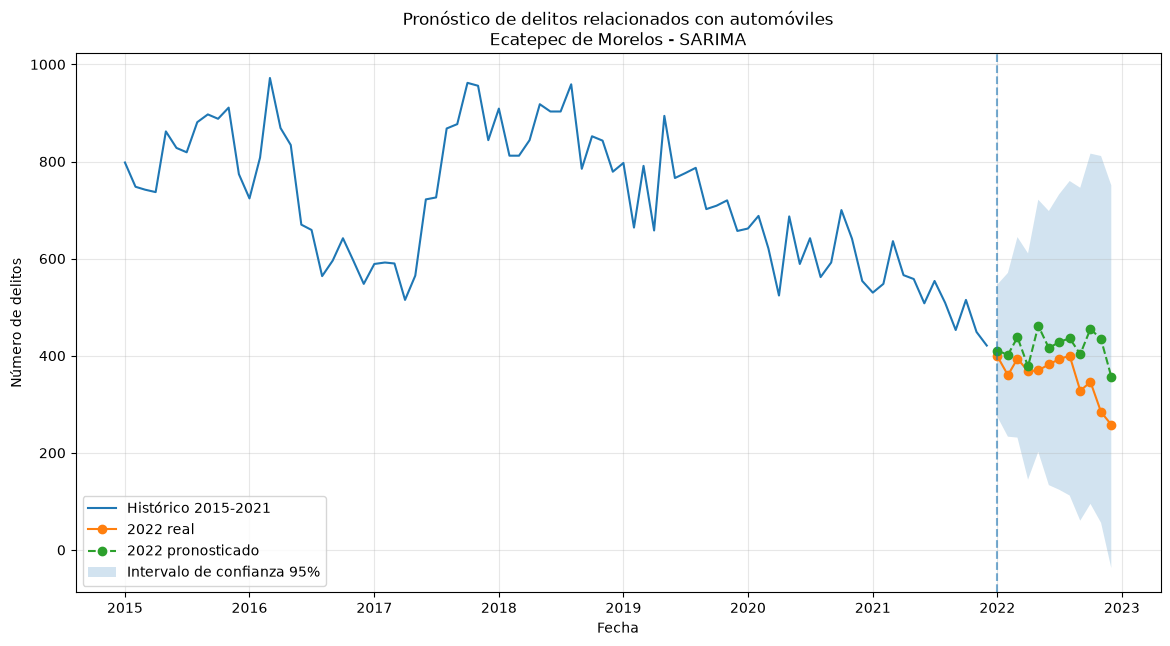

In [39]:
plt.figure(figsize=(14, 7))

# Histórico
plt.plot(
    serie_train.index,
    serie_train,
    label="Histórico 2015-2021"
)

# 2022 real
plt.plot(
    y_real.index,
    y_real,
    marker="o",
    label="2022 real"
)

# 2022 pronosticado
plt.plot(
    prediccion_2022.index,
    prediccion_2022,
    marker="o",
    linestyle="--",
    label="2022 pronosticado"
)

# Intervalo de confianza
plt.fill_between(
    intervalos_2022.index,
    intervalos_2022.iloc[:, 0],
    intervalos_2022.iloc[:, 1],
    alpha=0.2,
    label="Intervalo de confianza 95%"
)

plt.axvline(
    pd.Timestamp("2022-01-01"),
    linestyle="--",
    alpha=0.6
)

plt.title(
    "Pronóstico de delitos relacionados con automóviles\n"
    "Ecatepec de Morelos - SARIMA"
)

plt.xlabel("Fecha")
plt.ylabel("Número de delitos")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

**Lectura del pronóstico.** La gráfica contextualiza 2022 frente a toda la historia utilizada para entrenar el modelo. El pronóstico captura razonablemente el nivel general, pero los intervalos se amplían conforme aumenta el horizonte, reflejando mayor incertidumbre. Hacia finales de 2022 la incidencia real cae más rápido de lo previsto.


### Selección y evaluación del modelo

Después de comprobar que la serie original no era estacionaria mediante la
prueba de Dickey-Fuller Aumentada, se aplicó una primera diferenciación,
obteniendo posteriormente evidencia de estacionariedad.

Se evaluaron diferentes especificaciones ARIMA y SARIMA. Los modelos fueron
comparados inicialmente mediante los criterios AIC y BIC y posteriormente
mediante su capacidad para pronosticar los 12 meses de 2022, utilizando
MAE, RMSE y MAPE como métricas de error.

El modelo SARIMA(1,1,1)x(0,1,1,12) presentó el mejor desempeño, con un
MAE de 61.43 delitos mensuales, un RMSE de 74.06 y un MAPE de 18.80%.

La inclusión de un componente estacional de 12 meses permitió incorporar
al modelo tanto la evolución temporal de la incidencia delictiva como los
patrones anuales identificados previamente en la descomposición de la serie.

El modelo fue entrenado exclusivamente con información correspondiente al
periodo 2015-2021. Los datos reales de 2022 no participaron en el
entrenamiento y fueron utilizados únicamente para evaluar posteriormente
la capacidad predictiva del modelo.

- El modelo SARIMA logró reproducir razonablemente el comportamiento general observado durante 2022. Sin embargo, durante los últimos meses del año la incidencia real presentó una disminución superior a la esperada por el modelo. El MAPE de 18.80% evidencia una capacidad predictiva útil, aunque con un nivel de incertidumbre que debe considerarse al utilizar el pronóstico para decisiones de riesgo. Por ello, las predicciones deberían complementar, y no sustituir, otros indicadores utilizados para determinar las primas de seguro.

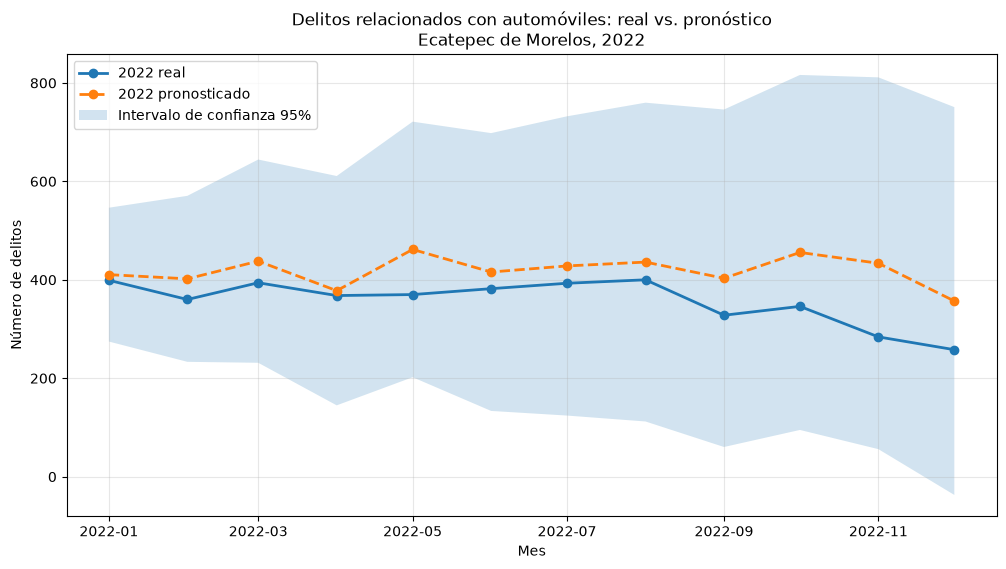

In [40]:
plt.figure(figsize=(12, 6))

plt.plot(
    y_real.index,
    y_real,
    marker="o",
    linewidth=2,
    label="2022 real"
)

plt.plot(
    prediccion_2022.index,
    prediccion_2022,
    marker="o",
    linestyle="--",
    linewidth=2,
    label="2022 pronosticado"
)

plt.fill_between(
    intervalos_2022.index,
    intervalos_2022.iloc[:, 0],
    intervalos_2022.iloc[:, 1],
    alpha=0.2,
    label="Intervalo de confianza 95%"
)

plt.title(
    "Delitos relacionados con automóviles: real vs. pronóstico\n"
    "Ecatepec de Morelos, 2022"
)

plt.xlabel("Mes")
plt.ylabel("Número de delitos")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

**Comparación enfocada en 2022.** Al aislar el periodo de prueba se observa con mayor claridad que el modelo tiende a sobreestimar varios meses, especialmente al cierre del año. Aun así, los valores reales permanecen dentro del intervalo de confianza mostrado. Para pricing, este pronóstico debe interpretarse como una señal de riesgo agregada y no como una predicción exacta de siniestros individuales.


## 5. Clasificación de estados por incidencia automotriz (K-Means)


In [41]:
df_2021 = df_auto_long[
    df_auto_long["Año"] == 2021
].copy()

print("Registros:", len(df_2021))
print("Entidades:", df_2021["Entidad"].nunique())
print("Delitos:", f'{df_2021["Delitos"].sum():,}')

Registros: 118944
Entidades: 32
Delitos: 128,474


**Base para clustering.** Se filtra exclusivamente 2021, año solicitado por la actividad. El conjunto contiene las 32 entidades y suma **128,474 delitos automotrices** bajo la definición utilizada en el proyecto.


In [42]:
# Crear variables para cada tipo de riesgo

df_2021["Auto_con_violencia"] = np.where(
    df_2021["Categoria_riesgo"] == "Robo de automóvil con violencia",
    df_2021["Delitos"],
    0
)

df_2021["Auto_sin_violencia"] = np.where(
    df_2021["Categoria_riesgo"] == "Robo de automóvil sin violencia",
    df_2021["Delitos"],
    0
)

df_2021["Autopartes"] = np.where(
    df_2021["Categoria_riesgo"] == "Robo de autopartes",
    df_2021["Delitos"],
    0
)

**Desagregación del riesgo.** Se crean columnas numéricas independientes para robo de automóvil con violencia, sin violencia y autopartes. Esto permite resumir después cada entidad mediante variables comparables.


In [43]:
estados_2021 = (
    df_2021
    .groupby(
        ["Clave_Ent", "Entidad"],
        as_index=False
    )
    .agg(
        Auto_con_violencia=("Auto_con_violencia", "sum"),
        Auto_sin_violencia=("Auto_sin_violencia", "sum"),
        Autopartes=("Autopartes", "sum"),
        Total_delitos=("Delitos", "sum")
    )
)

estados_2021.head()

,Clave_Ent,Entidad,Auto_con_violencia,Auto_sin_violencia,Autopartes,Total_delitos
0,1,Aguascalientes,74,704,836,1614
1,2,Baja California,1448,9427,52,10927
2,3,Baja California Sur,5,397,15,417
3,4,Campeche,6,70,29,105
4,5,Coahuila de Zaragoza,61,411,141,613


**Agregación estatal.** Los registros municipales/mensuales se consolidan por entidad. Cada fila de `estados_2021` representa ahora un estado y contiene las magnitudes de los principales tipos de riesgo automotriz.


In [44]:
print("Estados:", len(estados_2021))

estados_2021.sort_values(
    "Total_delitos",
    ascending=False
).head(10)

Estados: 32


,Clave_Ent,Entidad,Auto_con_violencia,Auto_sin_violencia,Autopartes,Total_delitos
14,15,México,16531,12810,3784,33125
8,9,Ciudad de México,1628,3948,8248,13824
13,14,Jalisco,4097,6051,1854,12002
1,2,Baja California,1448,9427,52,10927
20,21,Puebla,2726,3458,1180,7364
29,30,Veracruz de Ignacio de la Llave,1295,2936,154,4385
7,8,Chihuahua,475,3227,619,4321
16,17,Morelos,1399,1378,1347,4124
15,16,Michoacán de Ocampo,2027,1977,38,4042
10,11,Guanajuato,1948,1688,0,3636


**Exploración del ranking estatal.** El orden por delitos totales permite detectar valores extremos antes de aplicar clustering. Estado de México, Ciudad de México, Jalisco y Baja California destacan por volumen absoluto, por lo que es esperable que influyan fuertemente en las distancias entre observaciones.


In [45]:
estados_2021["Total_robo_auto"] = (
    estados_2021["Auto_con_violencia"] +
    estados_2021["Auto_sin_violencia"]
)

estados_2021["Pct_violencia"] = np.where(
    estados_2021["Total_robo_auto"] > 0,
    estados_2021["Auto_con_violencia"] /
    estados_2021["Total_robo_auto"] * 100,
    0
)

estados_2021["Pct_autopartes"] = np.where(
    estados_2021["Total_delitos"] > 0,
    estados_2021["Autopartes"] /
    estados_2021["Total_delitos"] * 100,
    0
)

estados_2021[
    [
        "Entidad",
        "Total_robo_auto",
        "Autopartes",
        "Total_delitos",
        "Pct_violencia",
        "Pct_autopartes"
    ]
].sort_values(
    "Total_delitos",
    ascending=False
).head(10).round(2)

,Entidad,Total_robo_auto,Autopartes,Total_delitos,Pct_violencia,Pct_autopartes
14,México,29341,3784,33125,56.34,11.42
8,Ciudad de México,5576,8248,13824,29.20,59.66
13,Jalisco,10148,1854,12002,40.37,15.45
1,Baja California,10875,52,10927,13.31,0.48
20,Puebla,6184,1180,7364,44.08,16.02
29,Veracruz de Ignacio de la Llave,4231,154,4385,30.61,3.51
7,Chihuahua,3702,619,4321,12.83,14.33
16,Morelos,2777,1347,4124,50.38,32.66
15,Michoacán de Ocampo,4004,38,4042,50.62,0.94
10,Guanajuato,3636,0,3636,53.58,0.00


**Variables derivadas.** Se calcula el robo total de automóvil, la proporción de robos con violencia y la participación de autopartes. Estas métricas permiten distinguir no sólo cuánto delito existe, sino también cómo se compone el riesgo en cada entidad.


In [46]:
variables_cluster = [
    "Total_robo_auto",
    "Autopartes",
    "Pct_violencia",
    "Pct_autopartes"
]

X = estados_2021[variables_cluster].copy()

X.describe().round(2)

,Total_robo_auto,Autopartes,Pct_violencia,Pct_autopartes
count,32.00,32.00,32.00,32.00
mean,3378.81,636.00,29.21,11.53
std,5399.22,1587.51,18.36,14.75
min,49.00,0.00,0.00,0.00
25%,844.75,19.50,15.51,1.29
50%,1802.00,63.50,26.20,5.58
75%,3652.50,562.75,41.30,15.53
max,29341.00,8248.00,75.52,59.66


**Primera especificación del clustering.** Se seleccionan cuatro variables: volumen de robo de automóvil, autopartes y dos porcentajes de composición. Esta primera aproximación busca detectar **perfiles** de riesgo, no únicamente niveles de incidencia.


In [47]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=variables_cluster,
    index=estados_2021.index
)

X_scaled.head()

,Total_robo_auto,Autopartes,Pct_violencia,Pct_autopartes
0,-0.489409,0.128000,-1.090143,2.773506
1,1.410598,-0.373759,-0.879663,-0.761562
2,-0.560163,-0.397439,-1.547687,-0.546566
3,-0.621508,-0.388479,-1.179620,1.108104
4,-0.546991,-0.316799,-0.901313,0.790049


**Estandarización.** `StandardScaler` centra cada variable y la expresa en unidades de desviación estándar. Es indispensable en K-Means porque el algoritmo utiliza distancias; sin estandarización, las variables con valores absolutos más grandes dominarían la formación de clusters.


In [48]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inercias = []
silhouettes = []

rango_k = range(2, 9)

for k in rango_k:

    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    etiquetas = modelo.fit_predict(X_scaled)

    inercias.append(modelo.inertia_)
    silhouettes.append(
        silhouette_score(X_scaled, etiquetas)
    )

**Búsqueda del número de clusters.** Se prueban valores de `k` entre 2 y 8 y se registran inercia y Silhouette. La inercia mide compactación interna; Silhouette combina cohesión y separación, donde valores más cercanos a 1 indican grupos mejor diferenciados.


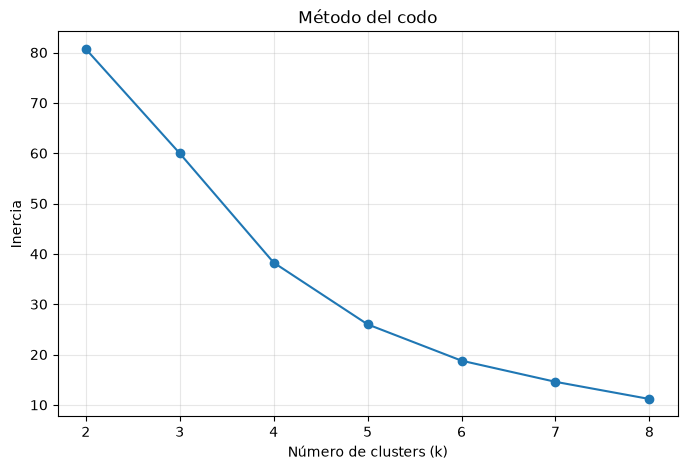

In [49]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(rango_k),
    inercias,
    marker="o"
)

plt.title("Método del codo")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Inercia")
plt.grid(alpha=0.3)

plt.show()

**Método del codo.** La inercia disminuye al aumentar `k`, como es esperable. La gráfica se utiliza para identificar el punto a partir del cual agregar grupos aporta mejoras cada vez menores; por sí sola no debe interpretarse como una regla automática.


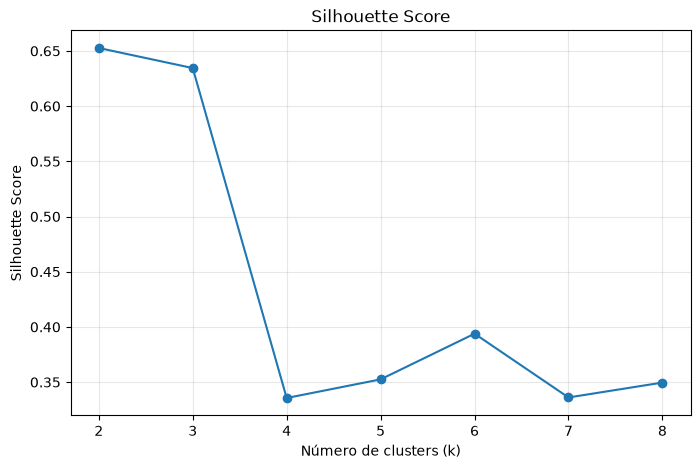

In [50]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(rango_k),
    silhouettes,
    marker="o"
)

plt.title("Silhouette Score")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Silhouette Score")
plt.grid(alpha=0.3)

plt.show()

**Silhouette de la primera especificación.** El mejor valor se obtiene con `k=2` (0.653), seguido por `k=3` (0.634). Ambos indican una separación razonablemente fuerte, aunque posteriormente se revisa si los grupos resultantes son útiles para el objetivo de “peligrosidad”.


In [51]:
pd.DataFrame({
    "k": list(rango_k),
    "Inercia": inercias,
    "Silhouette": silhouettes
}).round(3)

,k,Inercia,Silhouette
0,2,80.696,0.653
1,3,59.966,0.634
2,4,38.263,0.336
3,5,25.998,0.352
4,6,18.785,0.394
5,7,14.585,0.336
6,8,11.174,0.350


**Decisión exploratoria.** Se comparan conjuntamente ambos indicadores. Se prueba `k=3` por su mayor granularidad de negocio, pero el resultado posterior muestra que dos entidades atípicas quedan aisladas y 30 estados permanecen juntos.


In [52]:
from sklearn.cluster import KMeans

kmeans_final = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

estados_2021["Cluster"] = kmeans_final.fit_predict(X_scaled)

# Cantidad de estados por cluster
estados_2021["Cluster"].value_counts().sort_index()

Cluster
0    30
1     1
2     1
Name: count, dtype: int64

**Clustering exploratorio con cuatro variables.** Se ajusta K-Means con tres grupos para estudiar perfiles de riesgo. Los números 0, 1 y 2 son etiquetas arbitrarias del algoritmo y no representan por sí mismos niveles bajo, medio o alto.


In [53]:
estados_2021[
    [
        "Entidad",
        "Total_robo_auto",
        "Autopartes",
        "Pct_violencia",
        "Pct_autopartes",
        "Total_delitos",
        "Cluster"
    ]
].sort_values(
    ["Cluster", "Total_delitos"],
    ascending=[True, False]
).round(2)

,Entidad,Total_robo_auto,Autopartes,Pct_violencia,Pct_autopartes,Total_delitos,Cluster
13,Jalisco,10148,1854,40.37,15.45,12002,0
1,Baja California,10875,52,13.31,0.48,10927,0
20,Puebla,6184,1180,44.08,16.02,7364,0
29,Veracruz de Ignacio de la Llave,4231,154,30.61,3.51,4385,0
7,Chihuahua,3702,619,12.83,14.33,4321,0
16,Morelos,2777,1347,50.38,32.66,4124,0
15,Michoacán de Ocampo,4004,38,50.62,0.94,4042,0
10,Guanajuato,3636,0,53.58,0.00,3636,0
21,Querétaro,2905,544,16.25,15.77,3449,0
18,Nuevo León,2774,99,26.24,3.45,2873,0


**Inspección de integrantes.** La tabla permite observar qué estados forman cada cluster y qué características explican su asignación. Esta revisión es necesaria antes de asignar cualquier interpretación de negocio.


In [54]:
perfil_clusters = (
    estados_2021
    .groupby("Cluster")
    .agg(
        Estados=("Entidad", "count"),
        Prom_robo_auto=("Total_robo_auto", "mean"),
        Prom_autopartes=("Autopartes", "mean"),
        Prom_pct_violencia=("Pct_violencia", "mean"),
        Prom_pct_autopartes=("Pct_autopartes", "mean"),
        Prom_total_delitos=("Total_delitos", "mean")
    )
    .round(2)
)

perfil_clusters

,Estados,Prom_robo_auto,Prom_autopartes,Prom_pct_violencia,Prom_pct_autopartes,Prom_total_delitos
Cluster,,,,,,
0,30,2440.17,277.33,28.31,9.93,2717.5
1,1,5576.00,8248.00,29.20,59.66,13824.0
2,1,29341.00,3784.00,56.34,11.42,33125.0


**Perfil de los clusters exploratorios.** El resultado muestra un grupo de 30 entidades y dos grupos unitarios. Ciudad de México se distingue por autopartes, mientras Estado de México sobresale por robo vehicular y violencia. El hallazgo es válido como segmentación de perfiles, pero no produce tres niveles ordenados de peligrosidad.


In [55]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

componentes = pca.fit_transform(X_scaled)

estados_2021["PCA1"] = componentes[:, 0]
estados_2021["PCA2"] = componentes[:, 1]

print(
    "Varianza explicada:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

Varianza explicada: 80.35 %


**PCA para visualización.** Se reducen las cuatro variables estandarizadas a dos componentes principales. PCA no crea los clusters; únicamente facilita representarlos en un plano conservando la mayor cantidad posible de información.


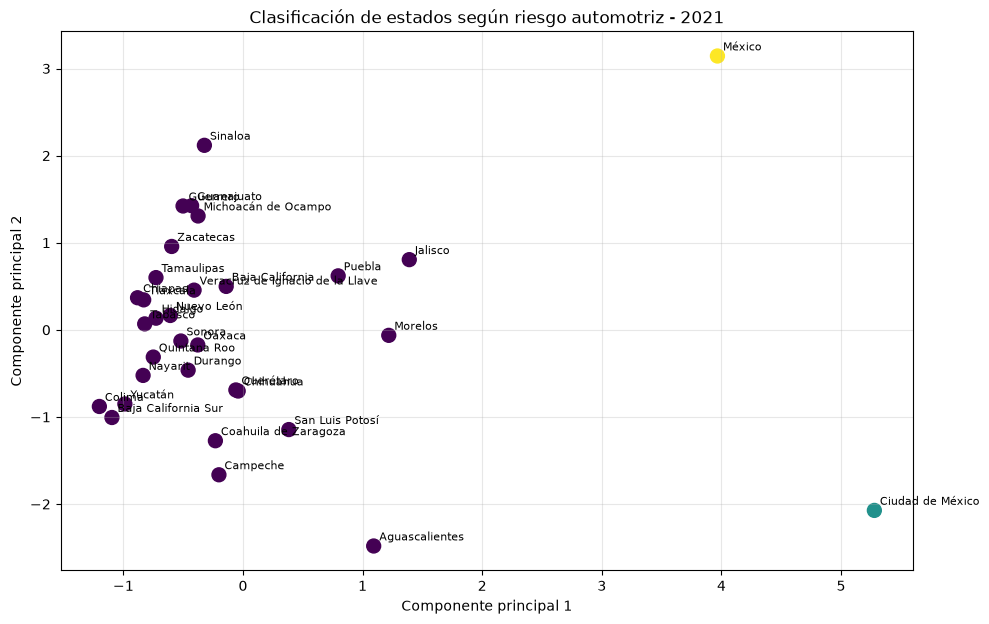

In [56]:
plt.figure(figsize=(11, 7))

scatter = plt.scatter(
    estados_2021["PCA1"],
    estados_2021["PCA2"],
    c=estados_2021["Cluster"],
    s=100
)

for _, row in estados_2021.iterrows():
    plt.annotate(
        row["Entidad"],
        (row["PCA1"], row["PCA2"]),
        fontsize=8,
        xytext=(4, 4),
        textcoords="offset points"
    )

plt.title("Clasificación de estados según riesgo automotriz - 2021")
plt.xlabel("Componente principal 1")
plt.ylabel("Componente principal 2")
plt.grid(alpha=0.3)

plt.show()

**Visualización PCA.** La separación de Ciudad de México y Estado de México confirma que poseen estructuras de riesgo muy diferentes del resto. La concentración de las demás entidades también explica por qué el primer clustering no funciona bien como una escala simple bajo–medio–alto.


### Determinación del número de clusters

Para determinar el número adecuado de grupos se evaluaron valores de k entre
2 y 8 utilizando el método del codo y el coeficiente Silhouette.

El mayor Silhouette Score se obtuvo con k=2 (0.653), seguido muy de cerca por
k=3 (0.634). Aunque dos clusters proporcionan la mayor separación matemática,
se seleccionaron tres clusters debido a que mantienen una calidad de
segmentación similar y permiten obtener una clasificación más útil e
interpretable para el negocio.

La utilización de tres grupos permite diferenciar distintos perfiles de riesgo
automotriz y facilita posteriormente su traducción en categorías útiles para
la estrategia de una compañía aseguradora.

Las variables utilizadas fueron previamente estandarizadas mediante
StandardScaler para evitar que las diferencias de escala influyeran en las
distancias calculadas por K-Means.

In [57]:
# Score basado en las variables estandarizadas

estados_2021["Score_riesgo"] = (
    X_scaled["Total_robo_auto"] * 0.40 +
    X_scaled["Autopartes"] * 0.25 +
    X_scaled["Pct_violencia"] * 0.25 +
    X_scaled["Pct_autopartes"] * 0.10
)

ranking_riesgo = (
    estados_2021[
        [
            "Entidad",
            "Total_robo_auto",
            "Autopartes",
            "Pct_violencia",
            "Pct_autopartes",
            "Total_delitos",
            "Cluster",
            "Score_riesgo"
        ]
    ]
    .sort_values("Score_riesgo", ascending=False)
    .reset_index(drop=True)
)

ranking_riesgo["Ranking"] = ranking_riesgo.index + 1

ranking_riesgo.head(32).round(2)

,Entidad,Total_robo_auto,Autopartes,Pct_violencia,Pct_autopartes,Total_delitos,Cluster,Score_riesgo,Ranking
0,México,29341,3784,56.34,11.42,33125,2,2.83,1
1,Ciudad de México,5576,8248,29.20,59.66,13824,1,1.71,2
2,Jalisco,10148,1854,40.37,15.45,12002,0,0.89,3
3,Puebla,6184,1180,44.08,16.02,7364,0,0.53,4
4,Morelos,2777,1347,50.38,32.66,4124,0,0.51,5
5,Sinaloa,2161,11,75.52,0.51,2172,0,0.37,6
6,Guanajuato,3636,0,53.58,0.00,3636,0,0.18,7
7,Baja California,10875,52,13.31,0.48,10927,0,0.17,8
8,Michoacán de Ocampo,4004,38,50.62,0.94,4042,0,0.17,9
9,Guerrero,1468,21,59.88,1.41,1489,0,0.11,10


**Análisis exploratorio no utilizado en el resultado final.** Se ensayó un score ponderado para ordenar entidades. Sin embargo, los pesos 40/25/25/10 serían una decisión subjetiva sin evidencia externa que los justifique. Por esa razón, este score **no se utiliza como clasificación final**; se conserva únicamente como registro del proceso exploratorio.


In [58]:
print("Varianza PC1:",
      round(pca.explained_variance_ratio_[0] * 100, 2), "%")

print("Varianza PC2:",
      round(pca.explained_variance_ratio_[1] * 100, 2), "%")

print("Varianza total explicada:",
      round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

Varianza PC1: 46.39 %
Varianza PC2: 33.97 %
Varianza total explicada: 80.35 %


**Capacidad de representación del PCA.** PC1 explica **46.39%** y PC2 **33.97%** de la varianza; juntos conservan **80.35%**. Por lo tanto, la gráfica bidimensional resume una proporción alta de la información original y es adecuada como apoyo visual.


In [59]:
cargas_pca = pd.DataFrame(
    pca.components_,
    columns=variables_cluster,
    index=["PC1", "PC2"]
)

cargas_pca.round(3)

,Total_robo_auto,Autopartes,Pct_violencia,Pct_autopartes
PC1,0.473,0.693,0.177,0.515
PC2,0.471,-0.102,0.695,-0.534


**Interpretación de componentes.** PC1 está asociado principalmente con autopartes (0.693), porcentaje de autopartes (0.515) y robo de automóvil (0.473), por lo que refleja sobre todo magnitud/autopartes. PC2 carga fuertemente en porcentaje de violencia (0.695) y robo de automóvil (0.471), y negativamente en porcentaje de autopartes (-0.534). Esto explica la posición diferenciada de CDMX y Estado de México.


In [60]:
variables_peligrosidad = [
    "Total_robo_auto",
    "Autopartes",
    "Total_delitos"
]

X_riesgo = estados_2021[variables_peligrosidad].copy()

scaler_riesgo = StandardScaler()

X_riesgo_scaled = scaler_riesgo.fit_transform(X_riesgo)

**Especificación descartada por redundancia.** Inicialmente se consideró incluir `Total_delitos` junto con robo de automóvil y autopartes. Como el total se deriva esencialmente de esas dos magnitudes, incorporarlo duplicaría información y otorgaría peso adicional al volumen. Por ello, la siguiente celda redefine correctamente el análisis con sólo dos variables.


In [61]:
variables_peligrosidad = [
    "Total_robo_auto",
    "Autopartes"
]

X_riesgo = estados_2021[variables_peligrosidad].copy()

scaler_riesgo = StandardScaler()
X_riesgo_scaled = scaler_riesgo.fit_transform(X_riesgo)

**Clustering definitivo de incidencia.** Para responder de forma más directa a la consigna de clasificar estados por peligrosidad/incidencia, se utilizan únicamente `Total_robo_auto` y `Autopartes`. Así se evita mezclar magnitud con porcentajes de composición y se obtiene una segmentación basada en el nivel observado de delitos.


In [62]:
inercias_riesgo = []
silhouettes_riesgo = []

rango_k = range(2, 9)

for k in rango_k:
    modelo = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    etiquetas = modelo.fit_predict(X_riesgo_scaled)

    inercias_riesgo.append(modelo.inertia_)
    silhouettes_riesgo.append(
        silhouette_score(X_riesgo_scaled, etiquetas)
    )

comparacion_k_riesgo = pd.DataFrame({
    "k": list(rango_k),
    "Inercia": inercias_riesgo,
    "Silhouette": silhouettes_riesgo
})

comparacion_k_riesgo.round(3)

,k,Inercia,Silhouette
0,2,23.733,0.827
1,3,9.653,0.821
2,4,3.695,0.661
3,5,2.432,0.450
4,6,1.673,0.444
5,7,1.029,0.484
6,8,0.658,0.476


**Selección de `k` en el modelo definitivo.** Con dos variables, `k=2` obtiene Silhouette **0.827** y `k=3` **0.821**. La diferencia es mínima, mientras que a `k=4` el indicador cae a **0.661**. Se conserva `k=3` para obtener mayor granularidad sin sacrificar de forma material la calidad de separación.


In [63]:
# Modelo K-Means definitivo para clasificación de peligrosidad

kmeans_riesgo = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

estados_2021["Cluster_riesgo"] = (
    kmeans_riesgo.fit_predict(X_riesgo_scaled)
)

estados_2021["Cluster_riesgo"].value_counts().sort_index()

Cluster_riesgo
0    30
1     1
2     1
Name: count, dtype: int64

**Ajuste final de K-Means.** Se entrenan tres clusters con semilla fija para reproducibilidad. Nuevamente, las etiquetas numéricas son arbitrarias; su significado se asigna después de estudiar los centroides y los integrantes.


In [64]:
resultado_clusters = (
    estados_2021[
        [
            "Entidad",
            "Total_robo_auto",
            "Autopartes",
            "Total_delitos",
            "Pct_violencia",
            "Cluster_riesgo"
        ]
    ]
    .sort_values(
        ["Cluster_riesgo", "Total_delitos"],
        ascending=[True, False]
    )
)

resultado_clusters.round(2)

,Entidad,Total_robo_auto,Autopartes,Total_delitos,Pct_violencia,Cluster_riesgo
13,Jalisco,10148,1854,12002,40.37,0
1,Baja California,10875,52,10927,13.31,0
20,Puebla,6184,1180,7364,44.08,0
29,Veracruz de Ignacio de la Llave,4231,154,4385,30.61,0
7,Chihuahua,3702,619,4321,12.83,0
16,Morelos,2777,1347,4124,50.38,0
15,Michoacán de Ocampo,4004,38,4042,50.62,0
10,Guanajuato,3636,0,3636,53.58,0
21,Querétaro,2905,544,3449,16.25,0
18,Nuevo León,2774,99,2873,26.24,0


**Resultado por entidad.** La clasificación confirma tres perfiles: un grupo general de 30 entidades, Estado de México como caso de muy alta incidencia de robo vehicular y Ciudad de México como caso excepcional de robo de autopartes.


In [65]:
perfil_riesgo = (
    estados_2021
    .groupby("Cluster_riesgo")
    .agg(
        Estados=("Entidad", "count"),
        Prom_robo_auto=("Total_robo_auto", "mean"),
        Prom_autopartes=("Autopartes", "mean"),
        Prom_total_delitos=("Total_delitos", "mean"),
        Min_total=("Total_delitos", "min"),
        Max_total=("Total_delitos", "max")
    )
    .round(2)
)

perfil_riesgo

,Estados,Prom_robo_auto,Prom_autopartes,Prom_total_delitos,Min_total,Max_total
Cluster_riesgo,,,,,,
0,30,2440.17,277.33,2717.5,52,12002
1,1,29341.00,3784.00,33125.0,33125,33125
2,1,5576.00,8248.00,13824.0,13824,13824


**Magnitud de los perfiles.** El cluster general promedia **2,440 robos de automóvil**, **277 robos de autopartes** y **2,718 delitos totales**. Estado de México registra **33,125** delitos totales y CDMX **13,824**. La gran distancia respecto del resto explica que K-Means los trate como grupos independientes.


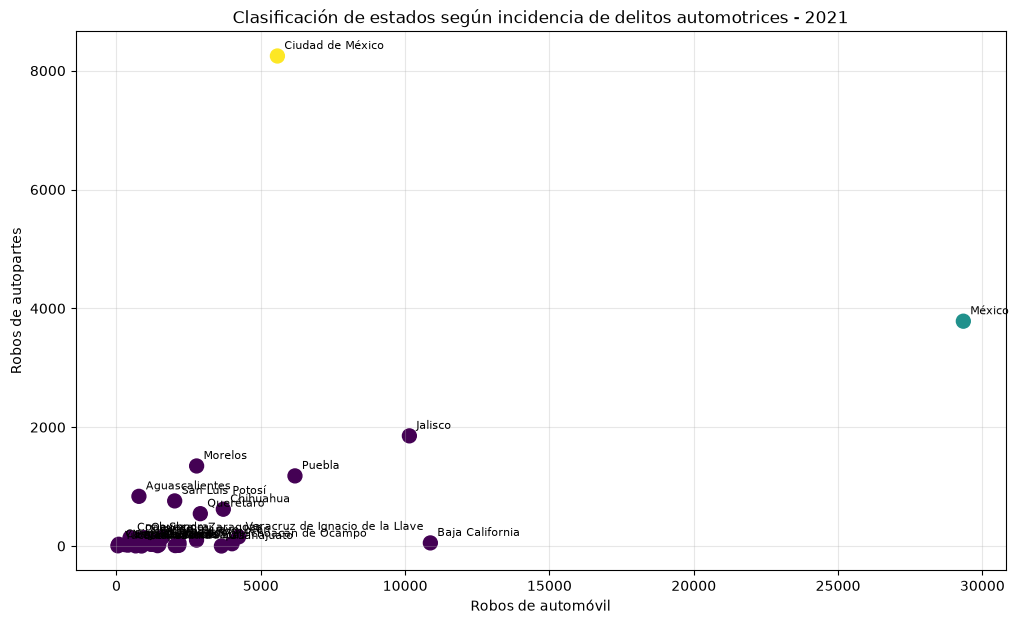

In [66]:
plt.figure(figsize=(12, 7))

scatter = plt.scatter(
    estados_2021["Total_robo_auto"],
    estados_2021["Autopartes"],
    c=estados_2021["Cluster_riesgo"],
    s=100
)

for _, row in estados_2021.iterrows():

    plt.annotate(
        row["Entidad"],
        (
            row["Total_robo_auto"],
            row["Autopartes"]
        ),
        fontsize=8,
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.title(
    "Clasificación de estados según incidencia de delitos automotrices - 2021"
)

plt.xlabel("Robos de automóvil")
plt.ylabel("Robos de autopartes")

plt.grid(alpha=0.3)

plt.show()

**Gráfica de dispersión del modelo final.** Los ejes muestran directamente las dos variables utilizadas por K-Means. Estado de México se separa por el elevado robo de automóviles (29,341), mientras CDMX se separa por autopartes (8,248). La mayoría de las entidades queda concentrada cerca del origen en comparación con estos dos valores extremos.


### Interpretación de los clusters

El modelo K-Means con k=3 identificó tres perfiles diferenciados de incidencia
delictiva automotriz durante 2021.

El Cluster 0 concentra 30 de las 32 entidades federativas. Estas entidades
presentan, en promedio, 2,440 robos de automóvil y 277 robos de autopartes,
con un promedio total de 2,718 delitos automotrices.

El Cluster 1 está compuesto exclusivamente por el Estado de México, que
presenta 33,125 delitos automotrices. Destaca particularmente por registrar
29,341 robos de automóvil, lo que lo convierte en un perfil de alta incidencia
de robo vehicular.

El Cluster 2 corresponde a Ciudad de México, con 13,824 delitos automotrices.
Su principal característica diferenciadora es el robo de autopartes, con
8,248 registros, cifra considerablemente superior a la observada en el resto
de las entidades.

Los resultados muestran que el riesgo automotriz no solamente varía en
magnitud entre entidades, sino también en su composición. Para una compañía
aseguradora, esta diferencia puede ser relevante al diseñar estrategias de
pricing y cobertura específicas según el tipo de riesgo predominante.

Debe considerarse que el análisis utiliza frecuencias absolutas de delitos.
Para estimar la probabilidad individual de siniestro sería recomendable
incorporar variables de exposición, como el parque vehicular asegurado o
registrado en cada entidad.

## 6. Preparación de resultados para mapa y Looker Studio


In [67]:
mapa_estados = estados_2021[
    [
        "Clave_Ent",
        "Entidad",
        "Total_robo_auto",
        "Autopartes",
        "Total_delitos",
        "Pct_violencia",
        "Cluster_riesgo"
    ]
].copy()

nombres_cluster = {
    0: "Perfil general",
    1: "Alta incidencia de robo vehicular",
    2: "Alta incidencia de robo de autopartes"
}

mapa_estados["Perfil_riesgo"] = (
    mapa_estados["Cluster_riesgo"].map(nombres_cluster)
)

mapa_estados = mapa_estados.sort_values(
    "Total_delitos",
    ascending=False
)

mapa_estados.head(10)

,Clave_Ent,Entidad,Total_robo_auto,Autopartes,Total_delitos,Pct_violencia,Cluster_riesgo,Perfil_riesgo
14,15,México,29341,3784,33125,56.340956,1,Alta incidencia de robo vehicular
8,9,Ciudad de México,5576,8248,13824,29.196557,2,Alta incidencia de robo de autopartes
13,14,Jalisco,10148,1854,12002,40.372487,0,Perfil general
1,2,Baja California,10875,52,10927,13.314943,0,Perfil general
20,21,Puebla,6184,1180,7364,44.081501,0,Perfil general
29,30,Veracruz de Ignacio de la Llave,4231,154,4385,30.607421,0,Perfil general
7,8,Chihuahua,3702,619,4321,12.830902,0,Perfil general
16,17,Morelos,2777,1347,4124,50.378106,0,Perfil general
15,16,Michoacán de Ocampo,4004,38,4042,50.624376,0,Perfil general
10,11,Guanajuato,3636,0,3636,53.575358,0,Perfil general


**Etiquetas de negocio.** En lugar de forzar las categorías “bajo, medio y alto”, los clusters se nombran según el patrón realmente observado: perfil general, alta incidencia de robo vehicular y alta incidencia de robo de autopartes. Esta interpretación es más fiel al resultado estadístico.


In [68]:
ruta_salida = r"C:\Users\samdl\Downloads\clasificacion_estados_2021.csv"

mapa_estados.to_csv(
    ruta_salida,
    index=False,
    encoding="utf-8-sig"
)

print("Archivo guardado en:")
print(ruta_salida)

Archivo guardado en:
C:\Users\samdl\Downloads\clasificacion_estados_2021.csv


**Exportación para visualización geográfica.** Se genera un archivo compacto con las 32 entidades y su perfil de riesgo. Este dataset está diseñado para construir el mapa estatal solicitado en Looker Studio y facilitar filtros o tablas de apoyo.


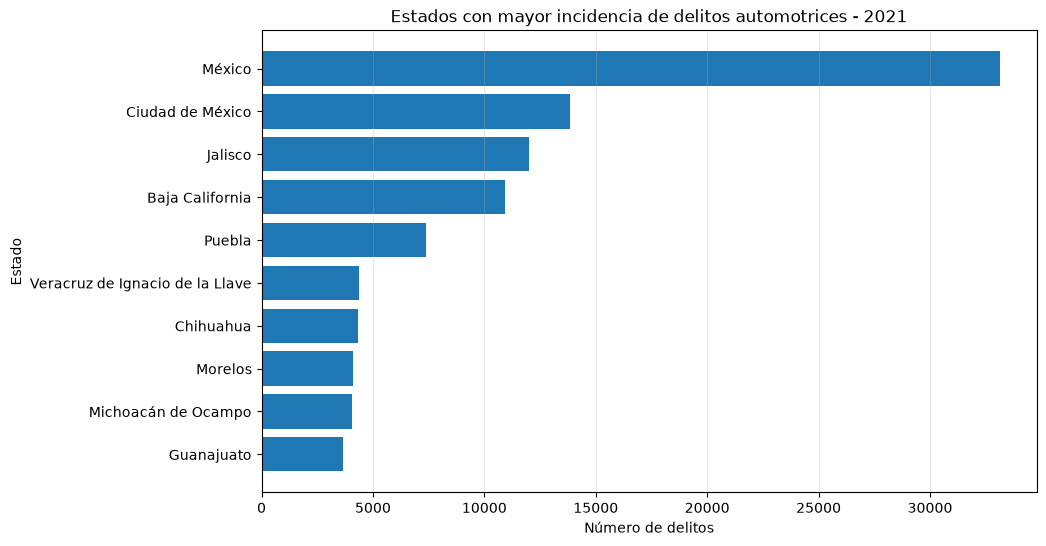

In [69]:
top_estados = (
    estados_2021
    .sort_values("Total_delitos", ascending=False)
    .head(10)
    .sort_values("Total_delitos")
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_estados["Entidad"],
    top_estados["Total_delitos"]
)

plt.title(
    "Estados con mayor incidencia de delitos automotrices - 2021"
)
plt.xlabel("Número de delitos")
plt.ylabel("Estado")

plt.grid(axis="x", alpha=0.3)

plt.show()

**Ranking visual.** La gráfica de barras resume los diez estados con mayor número absoluto de delitos automotrices en 2021. Estado de México lidera con amplia diferencia, seguido por CDMX, Jalisco y Baja California. Debe interpretarse como **frecuencia absoluta**, no como tasa de riesgo individual, porque no se ajusta por población ni parque vehicular.


In [70]:
ruta_looker = r"C:\Users\samdl\Downloads\datos_looker_automotriz.csv"

df_auto_long.to_csv(
    ruta_looker,
    index=False,
    encoding="utf-8-sig"
)

print("Archivo creado:")
print(ruta_looker)

Archivo creado:
C:\Users\samdl\Downloads\datos_looker_automotriz.csv


**Exportación detallada para Looker Studio.** Esta opción conserva el dataset largo completo y ofrece máxima flexibilidad de visualización, aunque puede producir un archivo pesado. Por ello se construye después una versión agregada más eficiente.


In [71]:
looker_historico = (
    df_auto_long
    .groupby(
        [
            "Fecha",
            "Año",
            "Mes",
            "Clave_Ent",
            "Entidad",
            "Cve. Municipio",
            "Municipio",
            "Categoria_riesgo"
        ],
        as_index=False
    )["Delitos"]
    .sum()
)

print(looker_historico.shape)

looker_historico.to_csv(
    r"C:\Users\samdl\Downloads\looker_historico_automotriz.csv",
    index=False,
    encoding="utf-8-sig"
)

(941508, 9)


**Dataset optimizado para dashboard.** Se agregan los delitos por fecha, entidad, municipio y categoría de riesgo antes de exportar. Esta estructura reduce filas redundantes y conserva las dimensiones necesarias para filtros, series temporales, rankings y mapas en Looker Studio.


## Conclusiones y observaciones metodológicas

1. **La selección del riesgo automotriz se realizó de forma trazable.** Primero se exploró el catálogo completo y después se restringió el análisis a robo de automóvil de cuatro ruedas y robo de autopartes, categorías directamente relacionadas con el problema asegurador.

2. **Ecatepec de Morelos fue elegido por evidencia cuantitativa.** Durante 2015–2021 concentró la mayor incidencia acumulada de los delitos automotrices seleccionados. La serie mostró cambios de tendencia y estacionalidad; la prueba ADF confirmó que la serie original no era estacionaria y que una primera diferencia era suficiente para estabilizarla.

3. **SARIMA superó a las alternativas evaluadas.** SARIMA(1,1,1)×(0,1,1,12) presentó el mejor desempeño fuera de muestra para 2022, con MAE de 61.43, RMSE de 74.06 y MAPE de 18.80%. El resultado es útil como referencia agregada de riesgo, pero conserva incertidumbre y no debe utilizarse de forma aislada para fijar primas.

4. **El clustering revela perfiles extremos, no una escala perfecta bajo–medio–alto.** Estado de México se diferencia por robo vehicular y CDMX por robo de autopartes, mientras las otras 30 entidades forman un grupo general. Esta estructura es un hallazgo de negocio: la naturaleza del riesgo puede variar tanto como su magnitud.

5. **Principal limitación.** Los rankings y clusters utilizan conteos absolutos. Estados con mayor población o parque vehicular pueden registrar más delitos simplemente por tener mayor exposición. Una siguiente versión del análisis debería incorporar tasas por cada 100 mil vehículos, cartera asegurada, frecuencia de siniestros, severidad económica y características del vehículo/conductor.

6. **Aplicación para una aseguradora.** Los resultados pueden apoyar segmentación geográfica, monitoreo de tendencias y diseño de coberturas. Para pricing real, deben complementarse con exposición y experiencia de siniestralidad propia de la compañía.


In [72]:
print("Filas:", f"{looker_historico.shape[0]:,}")
print("Columnas:", looker_historico.shape[1])
print("Celdas:", f"{looker_historico.shape[0] * looker_historico.shape[1]:,}")

Filas: 941,508
Columnas: 9
Celdas: 8,473,572


In [73]:
# looker no deja cargar archivos con más de 1 millón de filas, por lo que se generarán archivos separados por año

# ============================================================
# ARCHIVOS OPTIMIZADOS PARA LOOKER STUDIO
# ============================================================

# 1. Tendencia histórica mensual
looker_tendencia = (
    df_auto_long
    .groupby(
        ["Fecha", "Año", "Mes", "Categoria_riesgo"],
        as_index=False
    )["Delitos"]
    .sum()
)

# 2. Análisis municipal anual
looker_municipios = (
    df_auto_long
    .groupby(
        [
            "Año",
            "Clave_Ent",
            "Entidad",
            "Cve. Municipio",
            "Municipio",
            "Categoria_riesgo"
        ],
        as_index=False
    )["Delitos"]
    .sum()
)

# Exportación
looker_tendencia.to_csv(
    r"C:\Users\samdl\Downloads\looker_tendencia.csv",
    index=False,
    encoding="utf-8-sig"
)

looker_municipios.to_csv(
    r"C:\Users\samdl\Downloads\looker_municipios.csv",
    index=False,
    encoding="utf-8-sig"
)

# Comprobación
print("TENDENCIA")
print("Filas:", f"{len(looker_tendencia):,}")
print("Columnas:", looker_tendencia.shape[1])
print()

print("MUNICIPIOS")
print("Filas:", f"{len(looker_municipios):,}")
print("Columnas:", looker_municipios.shape[1])

TENDENCIA
Filas: 396
Columnas: 5

MUNICIPIOS
Filas: 78,459
Columnas: 7


In [74]:
# Solo lee los encabezados; NO carga los 2.5 millones de registros
df = pd.read_csv(ruta, nrows=0, encoding="latin1")

print(df.columns.tolist())

['Año', 'Clave_Ent', 'Entidad', 'Cve. Municipio', 'Municipio', 'Bien jurídico afectado', 'Tipo de delito', 'Subtipo de delito', 'Modalidad', 'Enero', 'Febrero', 'Marzo', 'Abril', 'Mayo', 'Junio', 'Julio', 'Agosto', 'Septiembre', 'Octubre', 'Noviembre', 'Diciembre']


In [76]:
%pip install pyodbc
import pyodbc

print(pyodbc.drivers())

Note: you may need to restart the kernel to use updated packages.
['SQL Server', 'SQL Server Native Client RDA 11.0', 'ODBC Driver 17 for SQL Server', 'PostgreSQL ODBC Driver(ANSI)', 'PostgreSQL ODBC Driver(UNICODE)', 'Microsoft Access Driver (*.mdb, *.accdb)', 'Microsoft Excel Driver (*.xls, *.xlsx, *.xlsm, *.xlsb)', 'Microsoft Access Text Driver (*.txt, *.csv)', 'Microsoft Access dBASE Driver (*.dbf, *.ndx, *.mdx)']



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [77]:
import pyodbc

server = r"SAMSLAP"
database = "Riesgo_Automotriz"

conexion = pyodbc.connect(
    f"DRIVER={{ODBC Driver 17 for SQL Server}};"
    f"SERVER={server};"
    f"DATABASE={database};"
    f"Trusted_Connection=yes;"
)

cursor = conexion.cursor()

print("✅ Conexión exitosa a SQL Server")
print("Servidor:", server)
print("Base de datos:", database)

✅ Conexión exitosa a SQL Server
Servidor: SAMSLAP
Base de datos: Riesgo_Automotriz


In [78]:
query = """
SELECT 
    TABLE_SCHEMA,
    TABLE_NAME
FROM INFORMATION_SCHEMA.TABLES
WHERE TABLE_TYPE = 'BASE TABLE';
"""

cursor.execute(query)

for fila in cursor.fetchall():
    print(f"{fila.TABLE_SCHEMA}.{fila.TABLE_NAME}")

dbo.Incidencia_Municipal


In [79]:
cursor.execute("""
SELECT COUNT(*) 
FROM dbo.Incidencia_Municipal;
""")

registros = cursor.fetchone()[0]

print(f"Registros actuales: {registros:,}")

Registros actuales: 0


In [81]:
import pandas as pd
import pyodbc
import time

# ============================================================
# CONFIGURACIÓN
# ============================================================

ruta_csv = r"C:\Users\samdl\Downloads\IDM_NM_dic25.csv"

server = r"SAMSLAP"
database = "Riesgo_Automotriz"

chunk_size = 25_000


# ============================================================
# CONEXIÓN A SQL SERVER
# ============================================================

conexion = pyodbc.connect(
    f"DRIVER={{ODBC Driver 17 for SQL Server}};"
    f"SERVER={server};"
    f"DATABASE={database};"
    f"Trusted_Connection=yes;"
)

cursor = conexion.cursor()

# Acelera mucho las inserciones masivas
cursor.fast_executemany = True

print("✅ Conexión exitosa a SQL Server")
print(f"Servidor: {server}")
print(f"Base de datos: {database}")
print()


# ============================================================
# SENTENCIA INSERT
# ============================================================

sql_insert = """
INSERT INTO dbo.Incidencia_Municipal (
    [Año],
    [Clave_Ent],
    [Entidad],
    [Cve. Municipio],
    [Municipio],
    [Bien jurídico afectado],
    [Tipo de delito],
    [Subtipo de delito],
    [Modalidad],
    [Enero],
    [Febrero],
    [Marzo],
    [Abril],
    [Mayo],
    [Junio],
    [Julio],
    [Agosto],
    [Septiembre],
    [Octubre],
    [Noviembre],
    [Diciembre]
)
VALUES (
    ?, ?, ?, ?, ?, ?, ?, ?, ?,
    ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?
);
"""


# ============================================================
# CARGA POR CHUNKS
# ============================================================

inicio = time.time()
total_insertado = 0

print("🚀 Iniciando carga del archivo...")
print("-" * 55)

for numero_chunk, chunk in enumerate(
    pd.read_csv(
        ruta_csv,
        chunksize=chunk_size,
        encoding="latin1"
    ),
    start=1
):

    # El CSV usa este nombre, mientras nuestra tabla SQL
    # utiliza "Cve. Municipio"
    chunk = chunk.rename(
        columns={"Cve Municipio": "Cve. Municipio"}
    )

    # Columnas numéricas
    columnas_numericas = [
        "Año",
        "Clave_Ent",
        "Cve. Municipio",
        "Enero",
        "Febrero",
        "Marzo",
        "Abril",
        "Mayo",
        "Junio",
        "Julio",
        "Agosto",
        "Septiembre",
        "Octubre",
        "Noviembre",
        "Diciembre"
    ]

    for columna in columnas_numericas:
        chunk[columna] = pd.to_numeric(
            chunk[columna],
            errors="coerce"
        )

    # NaN de pandas -> None para SQL Server
    chunk = chunk.astype(object).where(
        pd.notnull(chunk),
        None
    )

    datos = list(
        chunk[
            [
                "Año",
                "Clave_Ent",
                "Entidad",
                "Cve. Municipio",
                "Municipio",
                "Bien jurídico afectado",
                "Tipo de delito",
                "Subtipo de delito",
                "Modalidad",
                "Enero",
                "Febrero",
                "Marzo",
                "Abril",
                "Mayo",
                "Junio",
                "Julio",
                "Agosto",
                "Septiembre",
                "Octubre",
                "Noviembre",
                "Diciembre"
            ]
        ].itertuples(index=False, name=None)
    )

    try:
        cursor.executemany(sql_insert, datos)
        conexion.commit()

        total_insertado += len(datos)

        print(
            f"Chunk {numero_chunk:03d} | "
            f"{total_insertado:,} registros cargados"
        )

    except Exception as error:

        conexion.rollback()

        print("\n❌ ERROR DURANTE LA CARGA")
        print(f"Chunk: {numero_chunk}")
        print(f"Registros acumulados: {total_insertado:,}")
        print(error)

        raise


# ============================================================
# VALIDACIÓN FINAL
# ============================================================

cursor.execute("""
SELECT COUNT(*)
FROM dbo.Incidencia_Municipal;
""")

total_sql = cursor.fetchone()[0]

tiempo_total = time.time() - inicio

print("-" * 55)
print("🎉 CARGA FINALIZADA")
print(f"Registros insertados: {total_insertado:,}")
print(f"Registros en SQL:     {total_sql:,}")
print(f"Tiempo total:         {tiempo_total / 60:.2f} minutos")

cursor.close()
conexion.close()

✅ Conexión exitosa a SQL Server
Servidor: SAMSLAP
Base de datos: Riesgo_Automotriz

🚀 Iniciando carga del archivo...
-------------------------------------------------------
Chunk 001 | 25,000 registros cargados
Chunk 002 | 50,000 registros cargados
Chunk 003 | 75,000 registros cargados
Chunk 004 | 100,000 registros cargados
Chunk 005 | 125,000 registros cargados
Chunk 006 | 150,000 registros cargados
Chunk 007 | 175,000 registros cargados
Chunk 008 | 200,000 registros cargados
Chunk 009 | 225,000 registros cargados
Chunk 010 | 250,000 registros cargados
Chunk 011 | 275,000 registros cargados
Chunk 012 | 300,000 registros cargados
Chunk 013 | 325,000 registros cargados
Chunk 014 | 350,000 registros cargados
Chunk 015 | 375,000 registros cargados
Chunk 016 | 400,000 registros cargados
Chunk 017 | 425,000 registros cargados
Chunk 018 | 450,000 registros cargados
Chunk 019 | 475,000 registros cargados
Chunk 020 | 500,000 registros cargados
Chunk 021 | 525,000 registros cargados
Chunk 022 |

In [82]:
import pandas as pd
import pyodbc

# ============================================================
# CONEXIÓN A SQL SERVER
# ============================================================

conexion = pyodbc.connect(
    r"DRIVER={ODBC Driver 17 for SQL Server};"
    r"SERVER=SAMSLAP;"
    r"DATABASE=Riesgo_Automotriz;"
    r"Trusted_Connection=yes;"
)

# ============================================================
# CONSULTA DESDE PYTHON
# ============================================================

query = """
SELECT TOP 20
    [Año],
    [Clave_Ent],
    [Entidad],
    [Cve. Municipio],
    [Municipio],
    [Bien jurídico afectado],
    [Tipo de delito],
    [Subtipo de delito],
    [Modalidad],
    [Enero],
    [Febrero],
    [Marzo],
    [Abril],
    [Mayo],
    [Junio],
    [Julio],
    [Agosto],
    [Septiembre],
    [Octubre],
    [Noviembre],
    [Diciembre]
FROM dbo.Incidencia_Municipal;
"""

df_sql = pd.read_sql(query, conexion)

print("✅ Datos recuperados correctamente desde SQL Server")
print(f"Filas recuperadas: {len(df_sql)}")
print(f"Columnas recuperadas: {len(df_sql.columns)}")

display(df_sql)

conexion.close()

✅ Datos recuperados correctamente desde SQL Server
Filas recuperadas: 20
Columnas recuperadas: 21


C:\Users\samdl\AppData\Local\Temp\ipykernel_29320\1853961371.py:45: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df_sql = pd.read_sql(query, conexion)


,Año,Clave_Ent,Entidad,Cve. Municipio,Municipio,Bien jurídico afectado,Tipo de delito,Subtipo de delito,Modalidad,Enero,...,Marzo,Abril,Mayo,Junio,Julio,Agosto,Septiembre,Octubre,Noviembre,Diciembre
0,2015,1,Aguascalientes,1001,Aguascalientes,La vida y la Integridad corporal,Homicidio,Homicidio doloso,Con arma de fuego,2,...,1,1,0,1,1,0,2,1,0,1
1,2015,1,Aguascalientes,1001,Aguascalientes,La vida y la Integridad corporal,Homicidio,Homicidio doloso,Con arma blanca,1,...,0,0,0,1,0,1,0,0,0,0
2,2015,1,Aguascalientes,1001,Aguascalientes,La vida y la Integridad corporal,Homicidio,Homicidio doloso,Con otro elemento,0,...,1,1,3,2,0,1,2,0,0,0
3,2015,1,Aguascalientes,1001,Aguascalientes,La vida y la Integridad corporal,Homicidio,Homicidio doloso,No especificado,1,...,0,1,0,0,0,0,0,0,0,0
4,2015,1,Aguascalientes,1001,Aguascalientes,La vida y la Integridad corporal,Homicidio,Homicidio culposo,Con arma de fuego,0,...,0,0,1,0,0,0,0,0,0,0
5,2015,1,Aguascalientes,1001,Aguascalientes,La vida y la Integridad corporal,Homicidio,Homicidio culposo,Con arma blanca,0,...,0,0,0,0,0,0,0,0,0,0
6,2015,1,Aguascalientes,1001,Aguascalientes,La vida y la Integridad corporal,Homicidio,Homicidio culposo,En accidente de tránsito,9,...,3,11,6,4,6,6,11,6,3,7
7,2015,1,Aguascalientes,1001,Aguascalientes,La vida y la Integridad corporal,Homicidio,Homicidio culposo,Con otro elemento,0,...,0,0,0,1,0,0,0,0,0,0
8,2015,1,Aguascalientes,1001,Aguascalientes,La vida y la Integridad corporal,Homicidio,Homicidio culposo,No especificado,1,...,0,3,0,0,0,0,0,0,0,0
9,2015,1,Aguascalientes,1001,Aguascalientes,La vida y la Integridad corporal,Lesiones,Lesiones dolosas,Con arma de fuego,1,...,4,1,1,1,3,2,1,3,2,2
